---
# Crash and Casualty Data Analysis from 2021 to 2025 in South Australia
**Author:** Duc Tuong Phu Le  
**Format:**  
- HTML   
- PDF: Default  
---

## 1. Introduction

### 🎯 Overview & Purpose
Powered by official traffic data from **SA Government (2021–2025)**, this analysis translates complex multi-year crash records into actionable intelligence. 

Our core mission is to bridge the gap between data and real-world impact by serving two key stakeholders:
- **Policy Makers:** Providing empirical evidence to optimize road safety regulations, speed zones, and infrastructure investments.
- **Road Users:** Raising situational awareness through transparent, data-driven insights into high-risk driving conditions.

---

### 🔍 Core Analytical Pillars
To uncover the hidden patterns behind South Australian road incidents, this report investigates two distinct dimensions:

1. **Temporal Dynamics (The *When*):**  
   A comprehensive 5-year time-series breakdown across **Years, Months, Days, and Hours** to pinpoint critical peak hazard windows.

2. **Multifactorial Risk Combinations (The *Why* & *Where*):**  
   Deep-dive modeling into complex interactions between infrastructure controls, environmental factors, road conditions, and critical behavioral triggers (such as DUI and drug involvement) to evaluate their direct impact on **crash frequency vs. casualty severity**.

## 2. Dataset Overview & Variable Glossary

The raw dataset originates from official South Australian traffic crash records (2021–2025), comprising 28 primary attributes. To maintain transparency across our Exploratory Data Analysis (EDA) and risk modeling, the dataset variables are structured into distinct functional categories below:

### 📑 Variable Dictionary

| Attribute Name | Functional Category | Description & Expected Values |
| :--- | :--- | :--- |
| **`REPORT_ID`** | Identifier | Unique identification key assigned to each reported traffic crash. |
| **`UNIQUE_LOC`** | Spatial / GIS | Unique identifier mapping the specific spatial location of the incident. |
| **`ACCLOC_X`** / **`ACCLOC_Y`** | Spatial / GIS | Spatial coordinates (X/Y) representing the exact geographic crash site. |
| **`Stats Area`** | Geospatial | Statistical Area classification code designated by Australian Census metrics. |
| **`Suburb`** / **`Postcode`** | Geospatial | Local suburb name and 4-digit postal code where the crash occurred. |
| **`LGA Name`** | Geospatial | Local Government Area name responsible for local road infrastructure. |
| **`Crash Date Time`** | Temporal | Timestamp marking the exact date, month, year, and time of the incident. |
| **`DayNight`** | Temporal | Lighting condition flag specifying whether the crash occurred in *Daylight* or *Night*. |
| **`Total Units`** | Scale / Impact | Count of physical units involved (e.g., motor vehicles, cyclists, pedestrians). |
| **`Total Cas`** | Severity Target | Aggregate number of casualties (*Total Cas = Total Fats + Total SI + Total MI*). |
| **`Total Fats`** | Severity Target | Number of fatal injuries resulting directly from the crash within legal limits. |
| **`Total SI`** | Severity Target | Total Serious Injuries requiring immediate hospitalization. |
| **`Total MI`** | Severity Target | Total Minor Injuries requiring medical treatment without prolonged hospital stays. |
| **`CSEF Severity`** | Severity Target | Categorical crash severity scale rating (e.g., *Fatal, Serious Injury, Minor Injury, Property Damage Only*). |
| **`Area Speed`** | Infrastructure | Designated legal speed limit zone (km/h) at the incident location. |
| **`Position Type`** | Infrastructure | Roadway alignment topology (e.g., *Cross Road, T-Junction, Carriageway, Freeway*). |
| **`Horizontal Align`** | Infrastructure | Road geometry curve features (e.g., *Straight, Curved Left/Right*). |
| **`Vertical Align`** | Infrastructure | Vertical gradient features of the road (e.g., *Level, Crest, Slope*). |
| **`Other Feat`** | Infrastructure | Additional roadway features (e.g., *Bridge, Roundabout, Pedestrian Refuge*). |
| **`Traffic Ctrls`** | Infrastructure | Active traffic management devices present (e.g., *Traffic Signals, Stop/Give Way Signs, No Control*). |
| **`Road Surface`** | Environmental | Physical roadway pavement material condition (e.g., *Sealed, Unsealed*). |
| **`Moisture Cond`** | Environmental | Surface wetness status at the impact moment (e.g., *Dry, Wet, Standing Water*). |
| **`Weather Cond`** | Environmental | Atmospheric weather state (e.g., *Fine, Raining, Overcast, Fog/Mist*). |
| **`Crash Type`** | Incident Nature | Primary impact mechanism (e.g., *Rear End, Hit Fixed Object, Right Angle, Side Swipe*). |
| **`Unit Resp`** | Behavioral / Risk | Identification number of the primary unit deemed responsible for the crash cause. |
| **`Entity Code`** | Behavioral / Risk | Classification of the primary responsible unit (e.g., *Driver, Cyclist, Pedestrian*). |
| **`DUI Involved`** | Behavioral / Risk | Flag indicating alcohol impairment involvement beyond legal BAC limits. |
| **`Drugs Involved`** | Behavioral / Risk | Flag indicating illicit or prescription drug impairment in involved operators. |

---


## 3. Data Cleaning & Feature Engineering

To prepare the raw data for advanced Exploratory Data Analysis (EDA) and nested risk modeling, the following cleaning and transformation steps were executed:

- **Missing Value Handling:** Filtered out invalid entries (`Unknown`, `NaN`, `None`, empty strings) across environmental and infrastructure attributes to prevent distortion in risk calculations.
- **Temporal Feature Engineering:** Parsed the raw `Crash Date Time` timestamp to extract granular time-series attributes:
  - **Hierarchical Breakdown:** Extracted `Year`, `Quarter`, `Month`, `Day`, and `Hour` to map multi-year temporal trends and cyclical patterns.
  - **Behavioral Time Categorization:** Created the `Day Type` feature to isolate high-risk shifts between *Weekdays* and *Weekends*.
  - **Holiday Integration:** Appended the `Holiday` indicator flag to cross-examine traffic incidents during festive or public holiday periods against normal traffic flow.
- **Speed Binning (`Speed_Group`):** Grouped continuous `Area Speed` values into 5 operational risk zones: `<50`, `50 to <60`, `60 to <70`, `70 to 80`, and `Above 80 km/h`.
- **Road Topology Classification (`Road Group`):** Consolidated detailed `Position Type` records into 4 core structural categories: *Intersections*, *Carriageway*, *Freeway & Ramps*, and *Crossings*.
- **Traffic Control Normalization (`Control Sign`):** Simplified complex `Traffic Ctrls` features into a binary classification (*Control Sign* vs. *No Control Sign*) to measure infrastructure enforcement impact.
- **Statistical Significance Threshold ($N \ge 10$):** Implemented a minimum volume constraint for multi-variable scenario modeling to eliminate low-sample bias and ensure reliable casualty ratio evaluations.

---
## 4. Environment Setup & Libraries

To execute the data cleaning, modeling, and visualization pipelines in this report, the following Python libraries are loaded:

- **Data Manipulation:** `pandas`, `numpy`
- **Visualization:** `matplotlib.pyplot`,`seaborn`
---

##2. Data Overview 

###  Environment Setup & Libraries

To execute the data cleaning, modeling, and visualization pipelines 
in this report, the core Python libraries and datasets are initialized below:

In [0]:
!pip install -q holidays seaborn pyproj folium tabulate

import pandas as pd 
import numpy as np 
import holidays
import matplotlib.pyplot as plt
import seaborn as sns




Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### Dataset import and setup 

In [0]:
crash_data = pd.read_csv('/Volumes/sa_traffic_project/default/data/SA Crash.csv')
au_holiday = holidays.Australia()


pd.set_option('display.max_colwidth', None);


### Data Inspection: Initial Sample & Structure

To verify that the dataset loaded correctly and to inspect the initial values across spatial, temporal, and categorical fields, the first 5 records of the raw dataset are displayed below:

In [0]:
# Display the first 5 rows of the SA Crash dataset
crash_data.head()

,REPORT_ID,Stats Area,Suburb,Postcode,LGA Name,Total Units,Total Cas,Total Fats,Total SI,Total MI,...,Unit Resp,Entity Code,CSEF Severity,Traffic Ctrls,DUI Involved,Drugs Involved,ACCLOC_X,ACCLOC_Y,UNIQUE_LOC,Crash Date Time
0,2021-1-12/10/2026,2 Metropolitan,VIRGINIA,5120,CITY OF PLAYFORD,2,0,0,0,0,...,2,Driver Rider,1: PDO,No Control,NaN,NaN,1326227.35,1696803.21,1.326230e+13,10/8/2021 12:15
1,2021-2-12/10/2026,2 Metropolitan,MELROSE PARK,5039,CC MITCHAM,2,1,1,0,0,...,2,Pedestrian,4: Fatal,No Control,NaN,NaN,1325945.79,1664421.93,1.325950e+13,6/1/2021 11:54
2,2021-3-12/10/2026,2 Metropolitan,SEMAPHORE PARK,5019,CITY OF CHARLES STURT,2,0,0,0,0,...,1,Driver Rider,1: PDO,Roundabout,NaN,NaN,1317767.25,1679377.81,1.317770e+13,13/1/2021 11:45:00
3,2021-4-12/10/2026,2 Metropolitan,MARDEN,5070,"CC OF NORWOOD, PAYNEHAM AND ST. PETERS",2,0,0,0,0,...,1,Driver Rider,1: PDO,No Control,Y,NaN,1332264.42,1673848.29,1.332260e+13,1/1/2021 1:05
4,2021-5-12/10/2026,2 Metropolitan,PARAFIELD GARDENS,5107,CITY OF SALISBURY,2,0,0,0,0,...,1,Driver Rider,1: PDO,No Control,NaN,NaN,1329432.20,1688030.50,1.329430e+13,1/1/2021 1:07


In [0]:
# Create a summary dataframe to inspect data types, 
# missing value counts, and valid percentage for every column.

na_check_df = pd.DataFrame(
    {
        'Data Type': crash_data.dtypes.values,  
        'Missing Count': crash_data.isnull().sum().values,  
        'Valid Ratio': (
            (crash_data.notnull().sum() / len(crash_data)) * 100
        ).round(2).map('{:.2f}%'.format),},
    index=crash_data.columns,  )

na_check_df

,Data Type,Missing Count,Valid Ratio
REPORT_ID,object,0,100.00%
Stats Area,object,0,100.00%
Suburb,object,0,100.00%
Postcode,int64,0,100.00%
LGA Name,object,513,99.22%
Total Units,int64,0,100.00%
Total Cas,int64,0,100.00%
Total Fats,int64,0,100.00%
Total SI,int64,0,100.00%
Total MI,int64,0,100.00%


In [0]:
#Identify distinct values in Stats Area, Position Type, Horizontal Align, Vertical Align, Crash Type, Entity Code, CSEF Severity, Traffic Ctrls
def unique(cols):
    col = []
    result = []

    for c in cols:
        col.append(c)
        result.append(crash_data[c].unique())
    return pd.DataFrame({
        'Columnn': col,
        'Unique Values': result})


unique(['Stats Area','Position Type', 'Vertical Align', 'Crash Type', 'Entity Code', 'CSEF Severity','Traffic Ctrls' ])
    


,Columnn,Unique Values
0,Stats Area,"[2 Metropolitan, 3 Country, 1 City]"
1,Position Type,"[Divided Road, Other, Cross Road, T-Junction, Not Divided, Multiple, Freeway, Ramp Off, Ramp On, Y-Junction, One Way, Interchange, Pedestrian Crossing, Rail Crossing, Rail Xing, Crossover]"
2,Vertical Align,"[Level, Slope, Bottom of Hill, Crest of Hill, Unknown]"
3,Crash Type,"[Side Swipe, Hit Pedestrian, Hit Fixed Object, Head On, Hit Animal, Right Angle, Roll Over, Rear End, Right Turn, Left Road - Out of Control, Other, Hit Parked Vehicle, Hit Object on Road]"
4,Entity Code,"[Driver Rider, Pedestrian, Animal, Other, Passenger]"
5,CSEF Severity,"[1: PDO, 4: Fatal, 3: SI, 2: MI]"
6,Traffic Ctrls,"[No Control, Roundabout, Traffic Signals, Stop Sign, Give Way Sign, Other, Rail Xing - Flashing, Rail Xing - Boom, Rail Xing - No Control, Rail Xing-Traffic Signals]"


## 3. 🛠️ Data Cleaning & Feature Engineering

### Road  Categorization 
To reduce categorical cardinality and uncover macro-level spatial patterns, detailed roadway alignment types (`Position Type`) are consolidated into 5 primary structural groups:
- **Intersections:** Capturing complex crossing zones (`Cross Road`, `T-Junction`, `Y-Junction`, etc.).
- **Carriageway:** Standard roadway segments (`Divided Road`, `Not Divided`, `One Way`).
- **Freeway & Ramps:** High-speed controlled-access corridors (`Freeway`, `Ramp On/Off`, `Interchange`).
- **Crossings:** Pedestrian and railway intersection points.
- **Other:** Residual or unmapped categories

In [0]:
#simplify spatial risk analysis (Intersections, Carriageway, Freeway, Crossings, Other)
road_groups = []
for v in crash_data['Position Type']:
  if pd.isna(v):
    road_groups.append('Other')
  elif v in ['Cross Road', 'T-Junction', 'Y-Junction', 'Crossover', 'Multiple']:
    road_groups.append('Intersections')
  elif v in ['Divided Road', 'Not Divided', 'One Way']:
    road_groups.append('Carriageway')
  elif v in ['Freeway', 'Ramp On', 'Ramp Off', 'Interchange']:
    road_groups.append('Freeway & Ramps')
  elif v in ['Pedestrian Crossing', 'Rail Crossing', 'Rail Xing']:
    road_groups.append('Crossings')
  else:
    road_groups.append('Other')

crash_data['Road Group'] = road_groups;

### Traffic Control Normalization

To evaluate the overall impact of traffic enforcement and infrastructure signage, the granular `Traffic Ctrls` attribute is normalized into a binary categorical feature (`Control Sign` vs. `No Control Sign`). 

In [0]:
#Categorize Traffic Controls into 2 categorical values, includign Control Sign and No Control Sign
control_sign = []
for v in crash_data['Traffic Ctrls']: 
    if 'No Control' in v:
        control_sign.append('No Control Sign')
    else: 
        control_sign.append('Control Sign')
crash_data['Control Sign'] = control_sign

#Check 
print(
    (crash_data['Traffic Ctrls'].str.contains('No Control')).sum(),
    (crash_data['Control Sign'] == 'No Control Sign').sum())

print(crash_data['Control Sign'].value_counts())
# Move Control Sign next to Traffic Ctrls
target_col = crash_data.columns.get_loc('Traffic Ctrls')
sign_col_remove = crash_data.pop('Control Sign')
crash_data.insert(target_col +1, 'Control Sign', sign_col_remove);


43409 43409
Control Sign
No Control Sign    43409
Control Sign       22246
Name: count, dtype: int64


###Hierarchical Date Extraction

To enable multi-level temporal analysis, the raw `Crash Date Time` field is parsed into standardized datetime objects. 

To support granular time-series analysis and evaluate behavioral patterns across different temporal dimensions, we perform a comprehensive transformation of the timestamp features:

- **Datetime Parsing & Hierarchical Breakdown:** From this standardized timestamp, we systematically extract hierarchical components:
  - `Crash Time` (Hour)
  - `Crash Date` & `Day Name Incident`
  - `Month Incident` 
  - `Quarter Incident` 
  - `Year Incident`

- **Behavioral Day Classification (`Day Type`):**
  - **Weekday:** Monday through Friday
  - **Weekend:** Saturday and Sunday
- **Public Holiday Cross-Referencing (`Holiday`):** Generates a binary indicator flag (`Holiday` vs. `No Holiday`) to isolate festive or holiday-period crash dynamics from baseline traffic patterns.

In [0]:
#Handle Time Series 

crash_data['Crash Date Time'] = pd.to_datetime(
    crash_data['Crash Date Time'], 
    format='mixed', 
    dayfirst=True, 
    errors='coerce'
)

crash_data['Crash Date Time'] = crash_data['Crash Date Time'].dt.floor('min')

crash_data['Crash Date'] = crash_data['Crash Date Time'].dt.date
crash_data['Crash Time'] = crash_data['Crash Date Time'].dt.hour.astype('Int64')
crash_data['Year Incident'] = crash_data['Crash Date Time'].dt.year.astype('Int64')
crash_data['Quarter Incident'] = 'Q' + crash_data['Crash Date Time'].dt.quarter.astype('Int64').astype(str) + '-' + crash_data['Year Incident'].astype(str)
crash_data['Month Incident'] = crash_data['Crash Date Time'].dt.month_name()
crash_data['Day Name Incident'] = crash_data['Crash Date Time'].dt.day_name()

#Categorize days into Weekend and Weekday 
day_type = []
day_list = {
    'Weekday': ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday'], 
    'Weekend': ['Saturday', 'Sunday']}
for v in crash_data['Day Name Incident']:
    if v in day_list['Weekday']:
        day_type.append('Weekday')
    elif v in day_list['Weekend']:
        day_type.append('Weekend')
    else: 
        day_type.append('Not Recorded Incident Date')
crash_data['Day Type'] = day_type

#Identifying Holiday in Time Series 
min_year = int(crash_data['Year Incident'].min())
max_year = int(crash_data['Year Incident'].max())

sa_holiday = holidays.Australia(state='SA', years=range(min_year, max_year + 1))
sa_holiday_dates = list(sa_holiday.keys())

crash_data['Holiday'] = crash_data['Crash Date'].isin(sa_holiday_dates).map({
    True: 'Holiday',
    False: 'No Holiday'
})


### Stats Area Correction & Speed Feature Engineering

To prepare regional and continuous variables for risk modeling and exploratory analysis, two key transformations are applied:

- **Zone Normalization (`Stats Area`):** Cleaned **City**, **Metropolitan**, and **Country**.
- **Speed Binning (`Speed_Group`):** Grouped continuous `Area Speed` values into discrete operational bands (`Under 50`, `50 to <60`, `60 to <70`, `70 to 80`, `Above 80`, and `Other / Unknown`).


In [0]:
#Ceanign variables in Stats Area into City, metropolitan, Country
crash_data['Stats Area'] = crash_data['Stats Area'].replace({'1 City': 'City', '2 Metropolitan': 'Metropolitan', '3 Country': 'Country'})

#Creating new categorical columns on Area Speed
speed_groups = []
for v in crash_data['Area Speed']:
  if pd.isna(v):
    speed_groups.append('Other / Unknown')
  elif v < 50:
    speed_groups.append('Under 50')
  elif 50 <= v < 60:
    speed_groups.append('50 to <60')
  elif 60 <= v < 70:
    speed_groups.append('60 to <70')
  elif 70 <= v <= 80:
    speed_groups.append('70 to 80')
  else:
    speed_groups.append('Above 80')

crash_data['Speed_Group'] = speed_groups;


### Casualty Subset Extraction

To isolate and focus our analysis specifically on traffic incidents. This dedicated subset enables targeted evaluation of injury severity, spatial risk factors, and high-consequence crash patterns.

In [0]:
#Filtering data, which contains Casualty value
casualty_data = crash_data[crash_data['Total Cas']!=0];


### Data Cleaning Check

In [0]:
crash_data.head()

,REPORT_ID,Stats Area,Suburb,Postcode,LGA Name,Total Units,Total Cas,Total Fats,Total SI,Total MI,...,Road Group,Crash Date,Crash Time,Year Incident,Quarter Incident,Month Incident,Day Name Incident,Day Type,Holiday,Speed_Group
0,2021-1-12/10/2026,Metropolitan,VIRGINIA,5120,CITY OF PLAYFORD,2,0,0,0,0,...,Carriageway,2021-08-10,12,2021,Q3-2021,August,Tuesday,Weekday,No Holiday,Above 80
1,2021-2-12/10/2026,Metropolitan,MELROSE PARK,5039,CC MITCHAM,2,1,1,0,0,...,Other,2021-01-06,11,2021,Q1-2021,January,Wednesday,Weekday,No Holiday,Under 50
2,2021-3-12/10/2026,Metropolitan,SEMAPHORE PARK,5019,CITY OF CHARLES STURT,2,0,0,0,0,...,Intersections,2021-01-13,11,2021,Q1-2021,January,Wednesday,Weekday,No Holiday,60 to <70
3,2021-4-12/10/2026,Metropolitan,MARDEN,5070,"CC OF NORWOOD, PAYNEHAM AND ST. PETERS",2,0,0,0,0,...,Intersections,2021-01-01,1,2021,Q1-2021,January,Friday,Weekday,Holiday,60 to <70
4,2021-5-12/10/2026,Metropolitan,PARAFIELD GARDENS,5107,CITY OF SALISBURY,2,0,0,0,0,...,Carriageway,2021-01-01,1,2021,Q1-2021,January,Friday,Weekday,Holiday,50 to <60


## 3. Exploratory Data Analysis (EDA) & Distribution Analysis
This section is dedicated to uncovering underlying trends, evaluating statistical distributions, and investigating risk factors associated with South Australian traffic incidents. The analysis covers:
- **Univariate & Bivariate Distributions:** Utilizing custom analytical functions to inspect categorical frequencies, numerical spreads, and concentration metrics.
- **Temporal & Spatial Patterns:** Cross-examining incident frequencies across hourly, daily, seasonal, and regional dimensions (`Stats Area`, `Day Type`, `Holiday`).
- **Severity & Casualty Dynamics:** Evaluating how infrastructure controls (`Control Sign`), speed thresholds (`Speed_Group`), and road topologies (`Road Group`) correlate with accident frequency and casualty outcomes.

---

### Quantitative Severity & Injury Breakdown

To evaluate the average severity and scale of incidents, we analyze key numeric indicators—including units involved, total casualties, and specific injury tiers (Fatalities, Serious Injuries, and Minor Injuries)

Based on the breakdown, the total casualty count (`Total Cas` = **0.36**) is the exact sum of the individual injury categories:
- **Fatalities (`Total Fats`):** 0.01
- **Serious Injuries (`Total SI`):** 0.06
- **Minor Injuries (`Total MI`):** 0.29

The following analysis will focus primarily on the Total Crashes and Casulaty Occurence 

In [0]:
col = ['Total Units', 'Total Cas', 'Total Fats', 'Total SI', 'Total MI']
def qty(cols): 
    name = []
    mean = []
    for col in cols: 
        name.append(col) 
        mean.append(round(crash_data[col].mean(), 2))
    return pd.DataFrame({
        "Columns": name,
        "Avg per Incident": mean})

qty(col)

# The Totals Casualty = Total Fats + Total SI + Total MI. We focus on evaluating the percentage of Casulaty occurence on Total Incidents

,Columns,Avg per Incident
0,Total Units,2.13
1,Total Cas,0.36
2,Total Fats,0.01
3,Total SI,0.06
4,Total MI,0.29


### Daily Distribution & Outlier Analysis (Boxplot)

To evaluate the central tendency, data spread, and identify anomalies at a daily level. This statistical view highlights **Total Units** and **Total Casualties (`Total Cas`)**.

<Figure size 800x500 with 0 Axes>

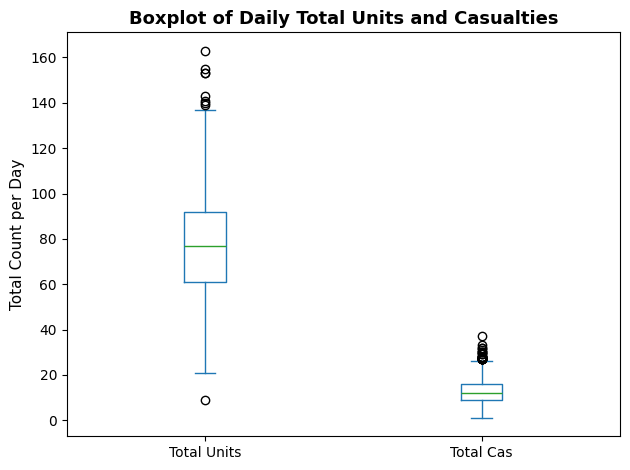

In [0]:
# Box Plot of Total Crashes and Casualties 
daily_total = crash_data.groupby('Crash Date')[['Total Units', 'Total Cas']].sum().reset_index()

plt.figure(figsize=(8, 5))
# Đổi grid=True thành grid=False để bỏ đường kẻ lưới
daily_total[['Total Units', 'Total Cas']].plot(kind='box', grid=False)

plt.title('Boxplot of Daily Total Units and Casualties', fontsize=13, fontweight='bold')
plt.ylabel('Total Count per Day', fontsize=11)
plt.tight_layout()
plt.show()

#### 🔍 Key Takeaways from Daily Boxplot Distribution

- **Total Units per Day:** Shows a wider variation with a median around **77 units per day** (IQR: **60 – 92 units**), featuring extreme high outliers reaching up to **160+ units**
- **Total Casualties per Day (`Total Cas`):** Remains consistently low with a median around **12 casualties per day** (IQR: **9 – 16 casualties**), though several peak outlier days exceed **30+ casualties**
---

### 📈 Temporal Trend Analysis (Yearly, Monthly, Daily & Hourly)

To uncover underlying temporal dynamics and peak risk windows, we evaluate the distribution of total crashes and casualties across four distinct temporal scales:
- **Yearly Trend (`Year Incident`)** 
- **Monthly Seasonality (`Month Incident`)** 
- **Weekly Distribution (`Day Name Incident`)** 
- **Hourly Progression (`Crash Time`)**

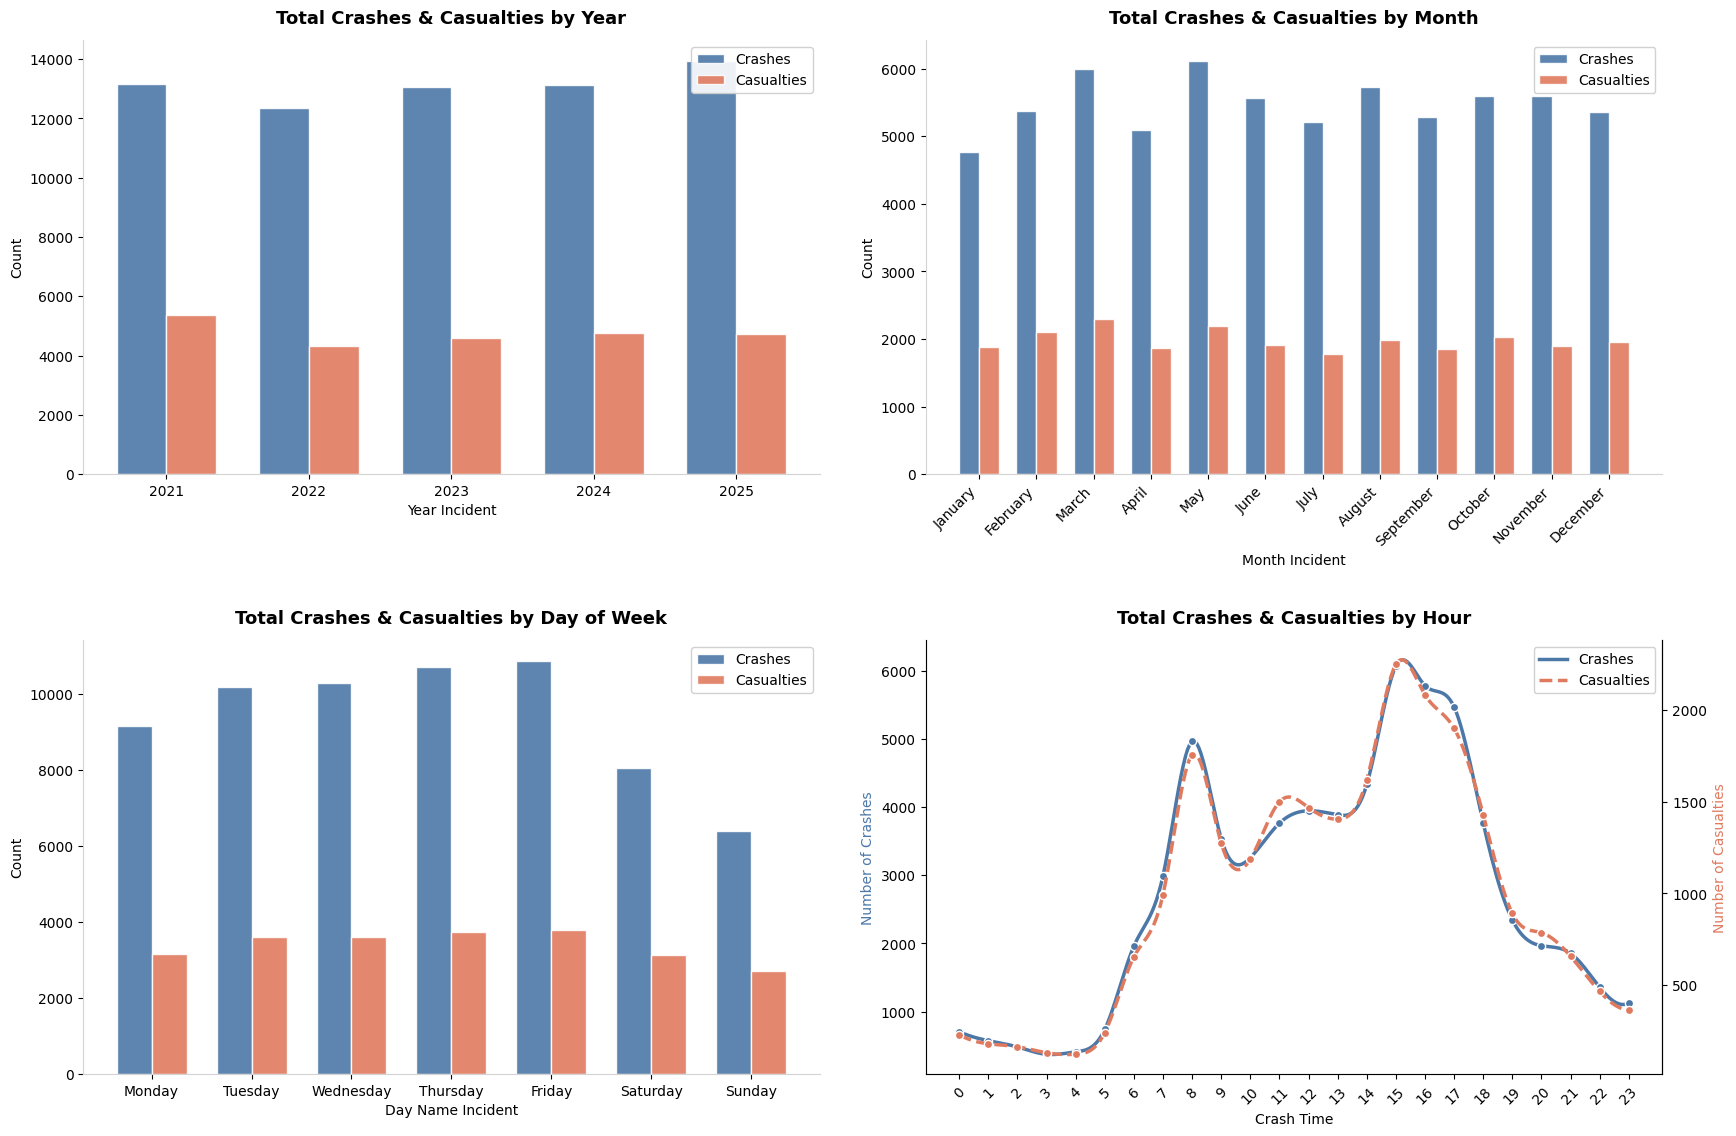

In [0]:

from scipy.interpolate import make_interp_spline

# year group
year_crash = crash_data.groupby('Year Incident').size().reset_index(name='Crashes')
year_casualty = (casualty_data.groupby('Year Incident')['Total Cas'].sum().reset_index(name='Casualties'))
chart_year_group = pd.merge(year_crash, year_casualty, on='Year Incident', how='outer').fillna(0).sort_values('Year Incident');

# Month group
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August','September', 'October', 'November', 'December']
month_crash = crash_data.groupby('Month Incident').size().reset_index(name='Crashes')
month_casualty = (casualty_data.groupby('Month Incident')['Total Cas'].sum().reset_index(name='Casualties'))
chart_month_group = pd.merge(month_crash, month_casualty, on='Month Incident', how='outer').fillna(0)
chart_month_group['Month Incident'] = pd.Categorical(chart_month_group['Month Incident'], categories=month_order, ordered=True)
chart_month_group = chart_month_group.sort_values('Month Incident');

# Day Group
day_order = ['Monday', 'Tuesday', 'Wednesday','Thursday', 'Friday', 'Saturday', 'Sunday']
day_crash = crash_data.groupby('Day Name Incident').size().reset_index(name='Crashes')
day_casualty = (casualty_data.groupby('Day Name Incident')['Total Cas'].sum().reset_index(name='Casualties'))
chart_day_group = pd.merge(day_crash, day_casualty, on='Day Name Incident', how='outer').fillna(0)
chart_day_group['Day Name Incident'] = pd.Categorical(chart_day_group['Day Name Incident'], categories=day_order, ordered=True)
chart_day_group = chart_day_group.sort_values('Day Name Incident');

# 4. TIme group
time_crash = crash_data.groupby('Crash Time').size().reset_index(name='Crashes').sort_values('Crash Time')
time_casualty = casualty_data.groupby('Crash Time')['Total Cas'].sum().reset_index(name='Casualties').sort_values('Crash Time')
chart_time_group = pd.merge(time_crash, time_casualty, on='Crash Time', how='outer').fillna(0).sort_values('Crash Time');


#Visualization
plt.style.use('default')
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.patch.set_facecolor('white')
width = 0.35 



# Crash & Cas by Year
x_year = np.arange(len(chart_year_group))
axes[0, 0].bar(x_year - width/2, chart_year_group['Crashes'], width, label='Crashes', color='#4C78A8', edgecolor='white', alpha=0.9)
axes[0, 0].bar(x_year + width/2, chart_year_group['Casualties'], width, label='Casualties', color='#E07A5F', edgecolor='white', alpha=0.9)

axes[0, 0].set_xticks(x_year)
axes[0, 0].set_xticklabels(chart_year_group['Year Incident'])
axes[0, 0].set_title('Total Crashes & Casualties by Year', fontsize=13, fontweight='bold', pad=12)
axes[0, 0].set_xlabel('Year Incident', fontsize=10)
axes[0, 0].set_ylabel('Count', fontsize=10)
axes[0, 0].legend(framealpha=0.9, facecolor='white', edgecolor='#cccccc')


# Crash & Cas by Month
x_month = np.arange(len(chart_month_group))
axes[0, 1].bar(x_month - width/2, chart_month_group['Crashes'], width, label='Crashes', color='#4C78A8', edgecolor='white', alpha=0.9)
axes[0, 1].bar(x_month + width/2, chart_month_group['Casualties'], width, label='Casualties', color='#E07A5F', edgecolor='white', alpha=0.9)

axes[0, 1].set_xticks(x_month)
axes[0, 1].set_xticklabels(chart_month_group['Month Incident'], rotation=45, ha='right')
axes[0, 1].set_title('Total Crashes & Casualties by Month', fontsize=13, fontweight='bold', pad=12)
axes[0, 1].set_xlabel('Month Incident', fontsize=10)
axes[0, 1].set_ylabel('Count', fontsize=10)
axes[0, 1].legend(framealpha=0.9, facecolor='white', edgecolor='#cccccc')


# Crash & Cas by Day
x_day = np.arange(len(chart_day_group))
axes[1, 0].bar(x_day - width/2, chart_day_group['Crashes'], width, label='Crashes', color='#4C78A8', edgecolor='white', alpha=0.9)
axes[1, 0].bar(x_day + width/2, chart_day_group['Casualties'], width, label='Casualties', color='#E07A5F', edgecolor='white', alpha=0.9)

axes[1, 0].set_xticks(x_day)
axes[1, 0].set_xticklabels(chart_day_group['Day Name Incident'])
axes[1, 0].set_title('Total Crashes & Casualties by Day of Week', fontsize=13, fontweight='bold', pad=12)
axes[1, 0].set_xlabel('Day Name Incident', fontsize=10)
axes[1, 0].set_ylabel('Count', fontsize=10)
axes[1, 0].legend(framealpha=0.9, facecolor='white', edgecolor='#cccccc')


# Crash & Cas by Time
x = np.arange(len(chart_time_group))
x_smooth = np.linspace(x.min(), x.max(), 300)

y_crash = chart_time_group['Crashes']
y_cas = chart_time_group['Casualties']

y_crash_smooth = make_interp_spline(x, y_crash, k=3)(x_smooth)
y_cas_smooth = make_interp_spline(x, y_cas, k=3)(x_smooth)

ax2_left = axes[1, 1]
ax2_right = ax2_left.twinx()

line1 = ax2_left.plot(x_smooth, y_crash_smooth, color='#4C78A8', linewidth=2.5, label='Crashes')
ax2_left.scatter(x, y_crash, color='#4C78A8', s=35, edgecolors='white', linewidths=1, zorder=5)

line2 = ax2_right.plot(x_smooth, y_cas_smooth, color='#E07A5F', linewidth=2.5, linestyle='--', label='Casualties')
ax2_right.scatter(x, y_cas, color='#E07A5F', s=35, edgecolors='white', linewidths=1, zorder=5)

ax2_left.set_xticks(x)
ax2_left.set_xticklabels(chart_time_group['Crash Time'])
ax2_left.tick_params(axis='x', rotation=45)

ax2_left.set_title('Total Crashes & Casualties by Hour', fontsize=13, fontweight='bold', pad=12)
ax2_left.set_xlabel('Crash Time', fontsize=10)
ax2_left.set_ylabel('Number of Crashes', fontsize=10, color='#4C78A8')
ax2_right.set_ylabel('Number of Casualties', fontsize=10, color='#E07A5F')

#Legend
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax2_left.legend(lines, labels, loc='upper right', framealpha=0.9, facecolor='white', edgecolor='#cccccc')

ax2_left.grid(False)
ax2_right.grid(False)
ax2_right.spines['top'].set_visible(False)


#Clean 

for ax in [axes[0, 0], axes[0, 1], axes[1, 0]]:
    ax.grid(False)
    ax.set_facecolor('white')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#D3D3D3')
    ax.spines['bottom'].set_color('#D3D3D3')

axes[1, 1].set_facecolor('white')
axes[1, 1].spines['top'].set_visible(False)
axes[1, 1].spines['left'].set_color('#D3D3D3')
axes[1, 1].spines['bottom'].set_color('#D3D3D3')


plt.tight_layout(pad=3)
plt.show()

#### 🔍 Key Takeaways from Temporal Trends

- **Yearly Trend:** Crash and casualty numbers remained **stable from 2021 to 2025**, with a slight peak in **2025**.
- **Monthly Seasonality:** Incidents peak during **mid-year months** (March, May, August), while **January** sees the fewest crashes.
- **Weekly Pattern:** **Weekdays** (Tuesday to Friday) record higher incident rates than weekends, peaking on **Friday**.
- **Hourly Progression:** Traffic incidents show two distinct rush-hour peaks: a morning peak at **8:00 AM** and a higher afternoon peak around **3:00 PM – 4:00 PM**.
---

### 📊 Comparative Summary Statistics & Analytical Pipeline

To systematically evaluate risk patterns across temporal, environmental, infrastructural, and behavioral dimensions, a custom analytical function (`get_summary_stats`) is implemented. This function computes normalized daily incident rates, daily casualty rates, and relative severity ratios across key segmented variables:

- **Temporal & Behavioral Factors:** Day/Night lighting conditions (`DayNight`), Weekday versus Weekend schedules (`Day Type`), and public holidays (`Holiday`).
- **Environmental & Infrastructure Factors:** Weather conditions (`Weather Cond`), road surface types (`Road Surface`), and traffic control presence (`Control Sign`).
- **Imputed Behavioral Risk Factors:** DUI and drug involvement flags (`DUI Involved`, `Drugs Involved`), handling missing data imputations to ensure accurate behavioral comparison.

In [0]:

def get_summary_stats(crash_df, casualty_df, col_name, val1, val2, val3=None):
    
    def calc(val):
        c_days = crash_df.loc[crash_df[col_name] == val, 'Crash Date'].nunique()
        cas_days = casualty_df.loc[casualty_df[col_name] == val, 'Crash Date'].nunique()
        
        total_crashes = crash_df.loc[crash_df[col_name] == val].shape[0]
        crash_per_day = round(total_crashes / c_days, 2) if c_days > 0 else 0
        
        total_cas = casualty_df.loc[casualty_df[col_name] == val, 'Total Cas'].sum()
        cas_per_day = round(total_cas / cas_days, 2) if cas_days > 0 else 0
        
        ratio = round((cas_per_day / crash_per_day) * 100, 2) if crash_per_day > 0 else 0
        
        return crash_per_day, cas_per_day, ratio
    v1_crash, v1_cas, v1_ratio = calc(val1)
    v2_crash, v2_cas, v2_ratio = calc(val2)
    
    data = {
        col_name: [val1, val2],
        'Crash per Day': [v1_crash, v2_crash],
        'Casualty per Day': [v1_cas, v2_cas],
        'Casualty Ratio Occurence': [v1_ratio, v2_ratio]
    }
    
    if val3 is not None:
        v3_crash, v3_cas, v3_ratio = calc(val3)
        data[col_name].append(val3)
        data['Crash per Day'].append(v3_crash)
        data['Casualty per Day'].append(v3_cas)
        data['Casualty Ratio Occurence'].append(v3_ratio)
        
    result_df = pd.DataFrame(data)
    return result_df


#Day Analysis Crash per day, Casualty per day and Casulaty Occurence on total Crashes base on Day and Night 
daynight_sum = get_summary_stats(crash_data, casualty_data, 'DayNight', 'Daylight', 'Night')

#Day Analysis Crash per day, Casualty per day and Casulaty Occurence on total Crashes base on Weekday and Weekend 

daytype_sum = get_summary_stats(crash_data, casualty_data, 'Day Type', 'Weekday', 'Weekend')

#Holiday Analysis Crash per day, Casualty per day and Casulaty Occurence on total Crashes base on Holiday and No Holiday 

holiday_type_sum = get_summary_stats(crash_data, casualty_data, 'Holiday', 'Holiday', 'No Holiday')

#Environemtal Analysis Crash per day, Casualty per day and Casulaty Occurence on total Crashes base on Weather 

weather_sum = get_summary_stats(crash_data, casualty_data, 'Weather Cond', 'Raining', 'Not Raining')

#Infrastructure Analysis on Crash per day, Casualty per day and Casulaty Occurence on total Crashes base on Control Sign 

road_sum = get_summary_stats(crash_data, casualty_data, 'Road Surface', 'Sealed',  'Unsealed')

#Infrastructure Analysis on Crash per day, Casualty per day and Casulaty Occurence on total Crashes base on Control Sign 
sign_sum = get_summary_stats(crash_data, casualty_data, 'Control Sign', 'Control Sign', 'No Control Sign')


# 1. NA Handling on Crash Data by creating a new dataset of Crash Data
crash_na_handle_data = crash_data.copy()
crash_na_handle_data['Drugs Involved'] = crash_na_handle_data['Drugs Involved'].fillna('N')
crash_na_handle_data['DUI Involved'] = crash_na_handle_data['DUI Involved'].fillna('N')

# 2. NA Handling on Casulaty Data by creating a new dataset of Casulaty Data
casualty_na_handle_data = casualty_data.copy()
casualty_na_handle_data['Drugs Involved'] = casualty_na_handle_data['Drugs Involved'].fillna('N')
casualty_na_handle_data['DUI Involved'] = casualty_na_handle_data['DUI Involved'].fillna('N')

# 3.Behavioral Analysin on Crash per day, Casualty per day and Casualty Occurence on total Crashes base on DUI and Drug Categorical Variables
dui_sum = get_summary_stats(crash_na_handle_data, casualty_na_handle_data, 'DUI Involved', 'Y', 'N')
drug_sum = get_summary_stats(crash_na_handle_data, casualty_na_handle_data, 'Drugs Involved', 'Y', 'N')




### 📋 Exploratory Summary Output 

To review and compare the computed risk metrics across all evaluated dimensions—spanning temporal schedules, environmental conditions, infrastructure controls, and behavioral risk factors—we compile the resulting summary dataframes 

In [0]:
summary_dict = {
    "1. Day/Night Analysis": daynight_sum,
    "2. Day Type Analysis": daytype_sum,
    "3. Holiday Analysis": holiday_type_sum,
    "4. Weather Analysis": weather_sum,
    "5. Road Surface Analysis": road_sum,
    "6. Control Sign Analysis": sign_sum,
    "7. DUI Involved": dui_sum,
    "8. Drug Involved": drug_sum
}

for title, df in summary_dict.items():
    print(f"\n--- {title} ---")
    display(df)  


--- 1. Day/Night Analysis ---


DayNight,Crash per Day,Casualty per Day,Casualty Ratio Occurence
Daylight,27.41,10.05,36.67
Night,8.59,3.41,39.7



--- 2. Day Type Analysis ---


Day Type,Crash per Day,Casualty per Day,Casualty Ratio Occurence
Weekday,39.28,13.73,34.95
Weekend,27.65,11.21,40.54



--- 3. Holiday Analysis ---


Holiday,Crash per Day,Casualty per Day,Casualty Ratio Occurence
Holiday,20.98,8.53,40.66
No Holiday,36.48,13.16,36.07


... (6 outputs left out)


--- 7. DUI Involved ---


DUI Involved,Crash per Day,Casualty per Day,Casualty Ratio Occurence
Y,1.8,1.69,93.89
N,34.77,12.31,35.4



--- 8. Drug Involved ---


Drugs Involved,Crash per Day,Casualty per Day,Casualty Ratio Occurence
Y,1.4,1.76,125.71
N,35.23,12.21,34.66


### Categorical Factors Proportion Analysis

To visually inspect the proportional distribution of key categorical risk and environmental factors within the crash dataset, a multi-panel grid of pie charts is generated. This visualization maps out the relative shares across seven major categorical variables:
- **Spatial & Environmental:** `Stats Area`, `DayNight`, `Road Surface`, and `Weather Cond` (or `Holiday`)
- **Infrastructure & Behavioral Controls:** `Control Sign`, `DUI Involved`, and `Drugs Involved` 

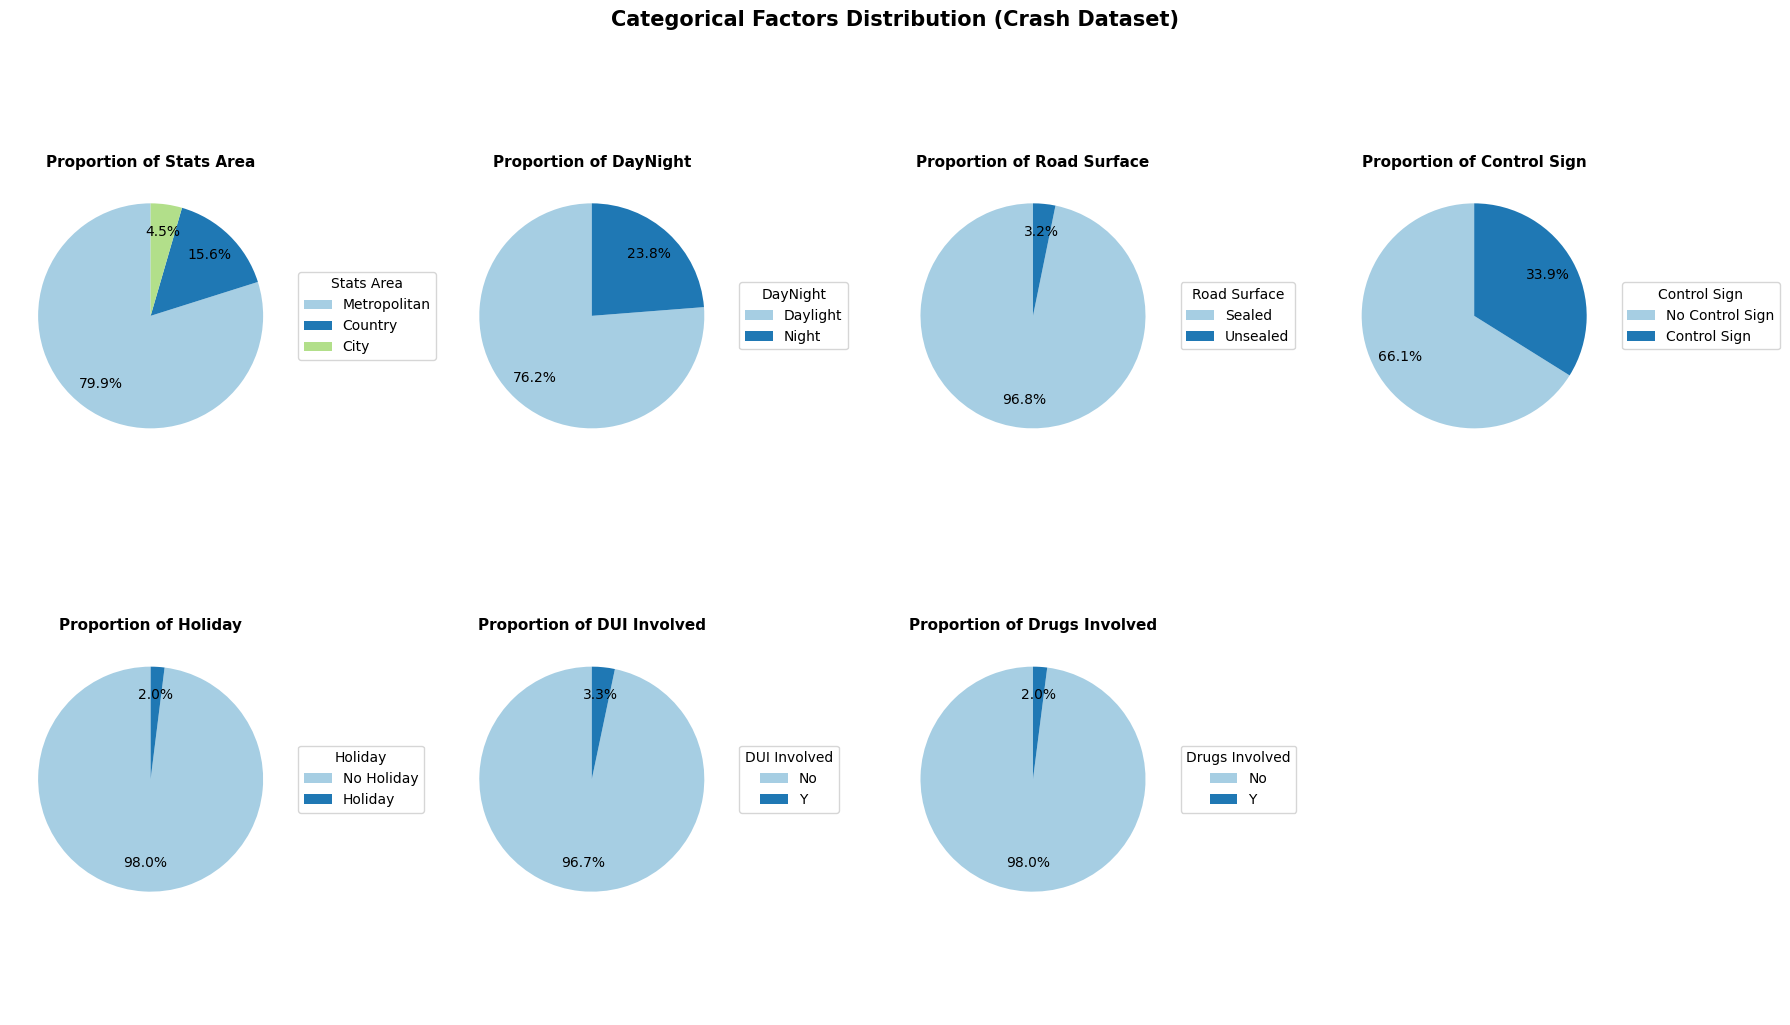

In [0]:
columns_to_plot = ['Stats Area', 'DayNight', 'Road Surface',  'Control Sign', 'Holiday', 'DUI Involved', 'Drugs Involved']

fig, axes = plt.subplots(2, 4, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(columns_to_plot):
    if col in crash_data.columns:
        s = crash_data[col].copy()
        
        if col in ['DUI Involved', 'Drugs Involved']:
            s = s.fillna('No')
        s = s.dropna()
        s = s[s != 'Unknown']
        
        data_counts = s.value_counts()
        
        wedges, texts, autotexts = axes[i].pie(data_counts, 
            autopct='%1.1f%%', 
            startangle=90,
            colors=plt.cm.Paired.colors,
            pctdistance=0.75)
        
        axes[i].legend(wedges,  data_counts.index, 
            title=col,
            loc="center left", 
            bbox_to_anchor=(1, 0, 0.5, 1))
        axes[i].set_title(f'Proportion of {col}', fontsize=11, fontweight='bold')
axes[-1].axis('off')

plt.suptitle('Categorical Factors Distribution (Crash Dataset)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

#### 🔍 Key Takeaways from Categorical Distribution

* **Spatial Concentration:** The vast majority of incidents occur in **Metropolitan (79.9%)** areas, followed by **Country (15.6%)** and **City (4.5%)** zones.
* **Environmental & Road Conditions:** Most crashes happen during **Daylight (76.2%)** and on **Sealed (96.8%)** road surfaces.
* **Infrastructure:** About **66.1%** of accidents occur at locations without control signs.
* **Behavioral & Special Factors:** Incidents occurring on public **Holidays (2.0%)**, involving **DUI (3.3%)**, or involving **Drugs (2.0%)** represent smaller shares of the overall dataset but highlight critical behavioral risk areas.
---

### Infrastructure & Environmental Impact Analysis

To evaluate how external conditions influence road safety, we analyze the daily average crash frequency, casualty volume, and injury ratios across six key infrastructure and environmental dimensions:
- **Day/Night Condition (`DayNight`)**
- **Day Type (`Day Type`)** 
- **Holiday Type (`Holiday`)**
- **Weather Condition (`Weather Cond`)**
- **Road Surface (`Road Surface`)** 
- **Control Sign (`Control Sign`)** 

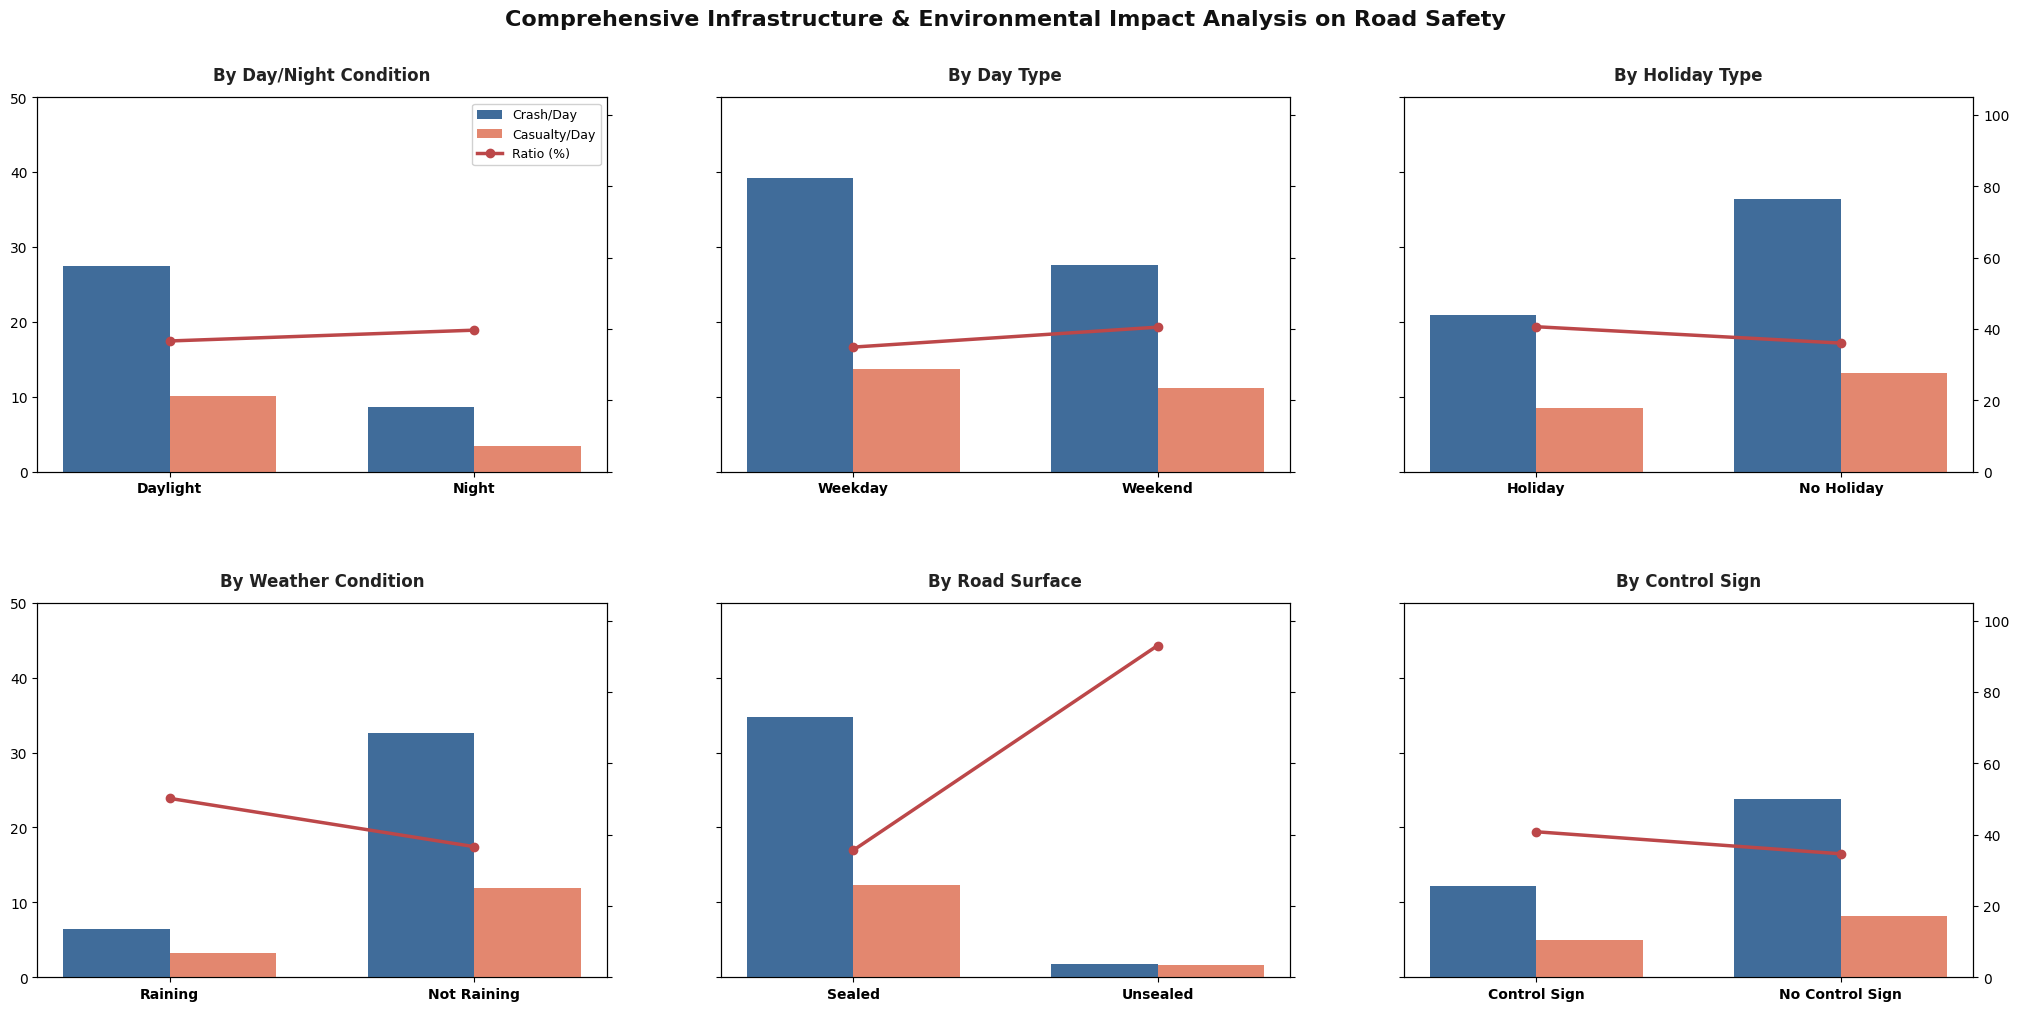

In [0]:

plt.style.use('default')
fig, axes = plt.subplots(2, 3, figsize=(22, 11))
axes = axes.flatten()
width = 0.35
#Data Prepareation
plots_config = [
    {'data': daynight_sum, 'x_col': 'DayNight', 'title': 'By Day/Night Condition', 'ylim_ax2': (0, 105)},
    {'data': daytype_sum, 'x_col': 'Day Type', 'title': 'By Day Type', 'ylim_ax2': (0, 105)},
    {'data': holiday_type_sum, 'x_col': 'Holiday', 'title': 'By Holiday Type', 'ylim_ax2': (0, 105)},
    {'data': weather_sum, 'x_col': 'Weather Cond', 'title': 'By Weather Condition', 'ylim_ax2': (0, 105)},
    {'data': road_sum, 'x_col': 'Road Surface', 'title': 'By Road Surface', 'ylim_ax2': (0, 105)},
    {'data': sign_sum, 'x_col': 'Control Sign', 'title': 'By Control Sign', 'ylim_ax2': (0, 105)}]

for i, config in enumerate(plots_config):
    ax1 = axes[i]
    ax2 = ax1.twinx()
    df = config['data']
    x_col = config['x_col']
    x = np.arange(len(df)) 
    #Plot
    bar1 = ax1.bar(x - width/2, df['Crash per Day'], width, label='Crash/Day', color='#2b5c8f', alpha=0.9, edgecolor='none', zorder=3)
    bar2 = ax1.bar(x + width/2, df['Casualty per Day'], width, label='Casualty/Day', color='#e07a5f', alpha=0.9, edgecolor='none', zorder=3)  
    line = ax2.plot(x, df['Casualty Ratio Occurence'], color='#bc4749', marker='o', linewidth=2.5, markersize=6, label='Ratio (%)', zorder=4)  
    #X, y setting
    ax1.set_xticks(x)
    ax1.set_xticklabels(df[x_col], fontweight='semibold', fontsize=10)
    ax1.set_ylim(0, 50)
    ax2.set_ylim(config['ylim_ax2'])
    ax1.grid(False)
    ax2.grid(False)
    if i % 3 != 0:
        ax1.set_yticklabels([])
    if i % 3 != 2:
        ax2.set_yticklabels([])
    #Label
    if i == 0:
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2, loc='upper right', framealpha=0.9, fontsize=9, facecolor='white', edgecolor='#cccccc')
    ax1.set_title(f"{config['title']}", fontweight='bold', fontsize=12, pad=12, color='#222222')
fig.suptitle('Comprehensive Infrastructure & Environmental Impact Analysis on Road Safety', fontsize=16, fontweight='bold', y=0.96, color='#111111')
plt.subplots_adjust(top=0.88, bottom=0.08, left=0.06, right=0.94, hspace=0.35, wspace=0.2)
plt.show()

#### 🔍 Day/Night Condition
* **Volume:** **Daylight** sees far more crashes (~28/day) than **Night** (~8/day).
* **Severity:** Injury ratios remain equal (~35% vs ~38%).
---
#### 🔍 Day Type
* **Volume:** **Weekdays** average higher daily crashes (~39/day) than **Weekends** 
* **Severity:** Casualty ratios stay stable across both
---
#### 🔍 Holiday Type
* **Volume:** **Non-holidays** account for most daily incidents
* **Severity:** Injury rates show negligible difference 
---
#### 🔍 Weather Condition
* **Volume:** Crashes concentrate mainly during **Dry weather**
* **Severity:** **Rain** increases crash severity, pushing the casualty ratio up to **48%** (vs **35%**)
---
#### 🔍 Road Surface
* **Volume:** **Sealed** roads account for almost all daily crashes 
* **Severity:** **Unsealed** roads carry extreme risk, with casualty ratios spiking to **~90%**
---
#### 🔍 Control Sign
* **Volume:** Uncontrolled locations (**No Sign**) see higher daily crashes
* **Severity:** Controlled sites (**Sign**) show a slightly higher injury ratio (**39%** vs **33%**)
---

###  Behavioral Factors Analysis: DUI & Drug Influence

To evaluate the impact of high-risk driver behavior on road safety, we examine the daily average crash frequency, casualty volume, and injury ratios:
- **DUI Involvement (`DUI Involved`)**
- **Drug Influence (`Drugs Involved`)** 

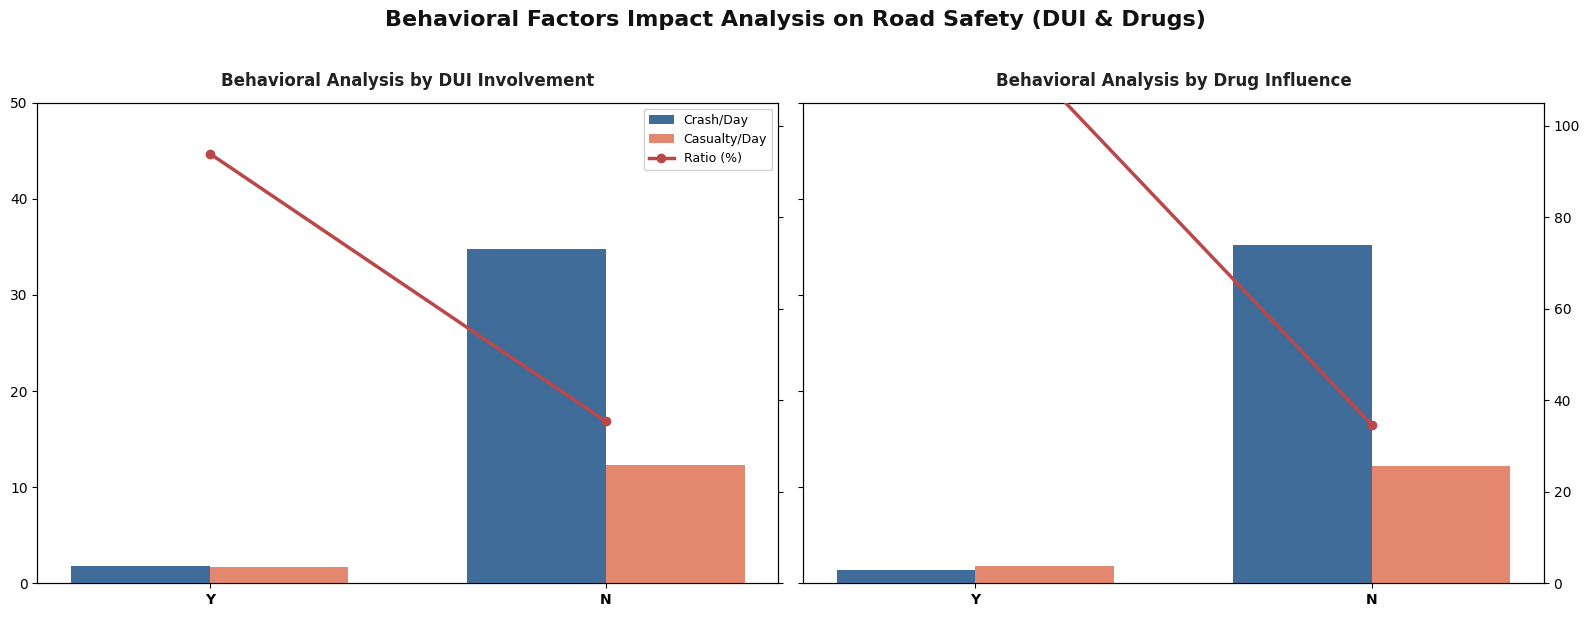

In [0]:
plt.style.use('default')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
width = 0.35
#Data Preparation 
plots_config = [{
        'data': dui_sum, 
        'x_col': 'DUI Involved', 
        'title': 'Behavioral Analysis by DUI Involvement', 
        'ylim_ax2': (0, 105)},
    {   'data': drug_sum, 
        'x_col': 'Drugs Involved', 
        'title': 'Behavioral Analysis by Drug Influence', 
        'ylim_ax2': (0, 105)}]

for i, config in enumerate(plots_config):
    ax1 = axes[i]
    ax2 = ax1.twinx()
    df = config['data']
    x_col = config['x_col']
    x = np.arange(len(df))
    
    #Plot
    bar1 = ax1.bar(x - width/2, df['Crash per Day'], width, label='Crash/Day', color='#2b5c8f', alpha=0.9, edgecolor='none', zorder=3)
    bar2 = ax1.bar(x + width/2, df['Casualty per Day'], width, label='Casualty/Day', color='#e07a5f', alpha=0.9, edgecolor='none', zorder=3)
    line = ax2.plot(x, df['Casualty Ratio Occurence'], color='#bc4749', marker='o', linewidth=2.5, markersize=6, label='Ratio (%)', zorder=4)
    # x y setting
    ax1.set_xticks(x)
    ax1.set_xticklabels(df[x_col], fontweight='semibold', fontsize=10)
    ax1.set_ylim(0, 50)
    ax2.set_ylim(config['ylim_ax2'])
    ax1.grid(False)
    ax2.grid(False)

    if i == 0:
        ax2.set_yticklabels([])
    else:
        ax1.set_yticklabels([])

    if i == 0:
        lines, labels = ax1.get_legend_handles_labels()
        lines2, labels2 = ax2.get_legend_handles_labels()
        ax1.legend(lines + lines2, labels + labels2, loc='upper right', framealpha=0.9, fontsize=9, facecolor='white', edgecolor='#cccccc')
    ax1.set_title(f"{config['title']}", fontweight='bold', fontsize=12, pad=12, color='#222222')

fig.suptitle('Behavioral Factors Impact Analysis on Road Safety (DUI & Drugs)', fontsize=16, fontweight='bold', y=1.02, color='#111111')
plt.tight_layout()
plt.show()

#### 🔍 DUI Involvement
* **Volume:** **Non-DUI** incidents account for the vast majority of daily crashes
* **Severity:** **DUI** crashes carry significantly higher severity, with the casualty ratio reaching **~94%** (compared to ~35% for Non-DUI).
---
#### 🔍 Drug Influence
* **Volume:** **Non-Drug** related incidents dominate overall daily volume 
* **Severity:** **Drug involvement** exhibits extreme severity, resulting in a casualty ratio exceeding **100%** per crash incident.
---

### Multi-Factor Risk Scenario Analysis: Objective vs. Behavioral Combinations
- **Objective Factors (`Top 10 High-Risk Scenarios by Objective Factors`):** Examines complex combinations of environmental and infrastructure variables, including day/night conditions, day types, holidays, control signs, and road surfaces.
- **Behavioral Factors (`Top 10 High-Risk Scenarios by Behavioral Factors`):** Evaluates high-risk intersections involving substance impairment (DUI and drug involvement) combined with environmental contexts.


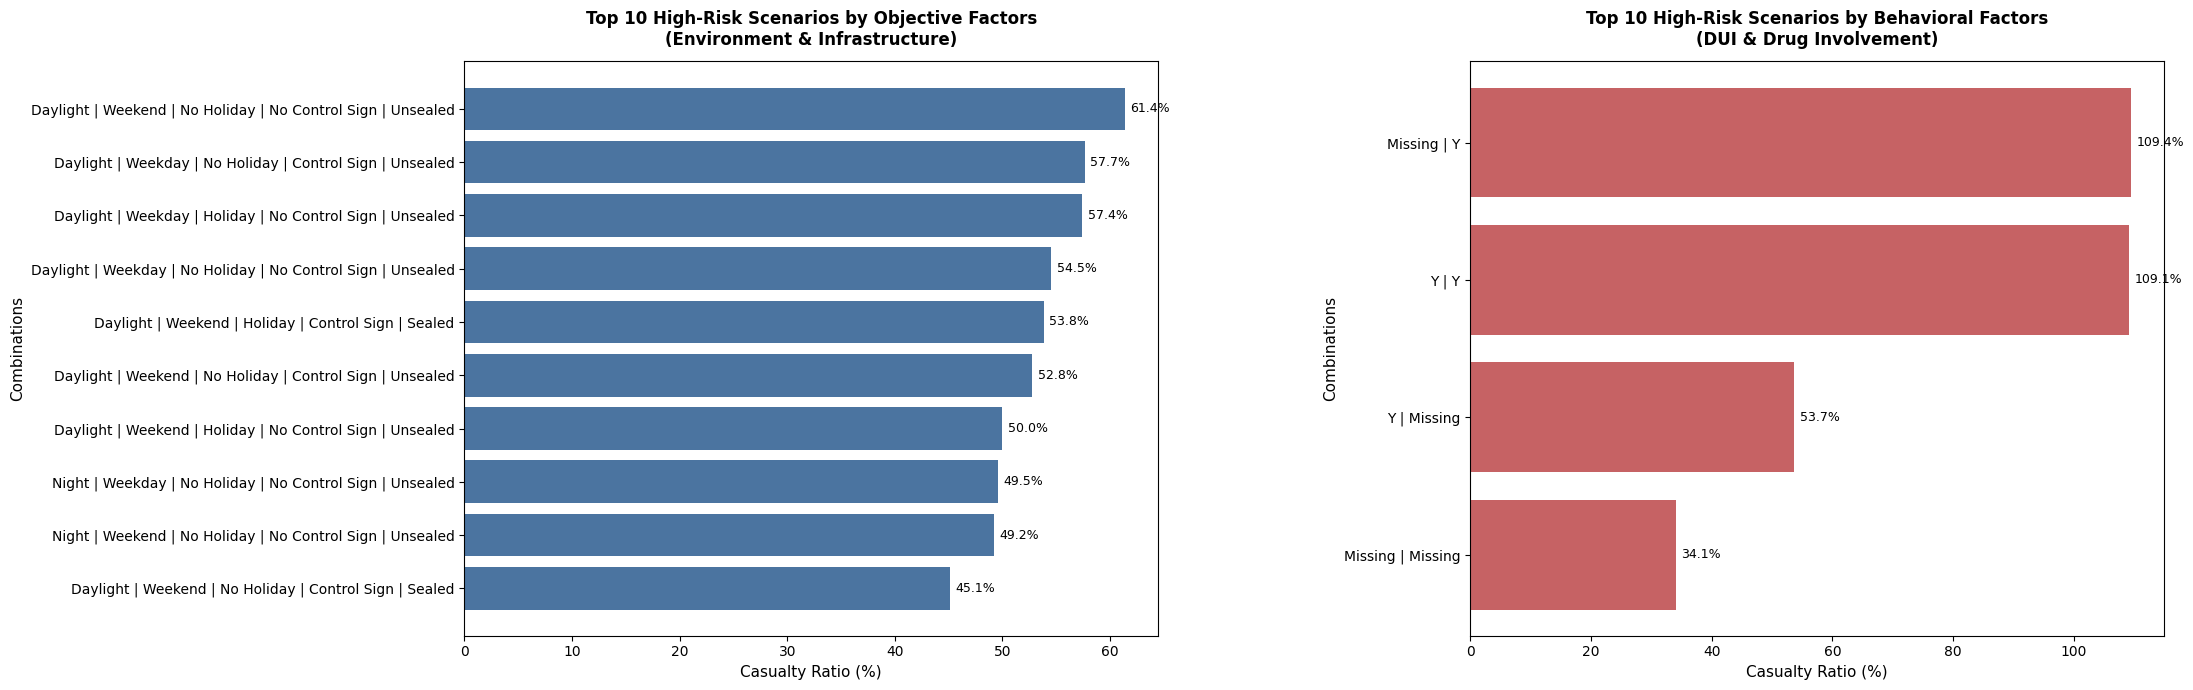

In [0]:
# 1. Objective Data Preparation
group_cols_obj = ['DayNight', 'Day Type', 'Holiday', 'Control Sign', 'Road Surface']

multi_group_obj = (
    crash_data.groupby(group_cols_obj, dropna=False)
    .agg(
        Total_Crashes=('REPORT_ID', 'count'),
        Total_Casualties=('Total Cas', 'sum')
    )
    .reset_index()
)
multi_group_obj['Casualty_Ratio'] = np.where(
    multi_group_obj['Total_Crashes'] > 0,
    (multi_group_obj['Total_Casualties'] / multi_group_obj['Total_Crashes']) * 100,
    0.0
)
multi_group_obj['Scenario'] = (
    multi_group_obj[group_cols_obj]
    .fillna('Missing')
    .astype(str)
    .agg(' | '.join, axis=1)
)
multi_group_obj = multi_group_obj[multi_group_obj['Total_Crashes'] >= 5]
top_risks_obj = multi_group_obj.sort_values(by='Casualty_Ratio', ascending=False).head(10)

# 2. Behavior Data Preparation, DUI & Drug
group_cols_beh = ['DUI Involved', 'Drugs Involved']

multi_group_beh = (
    crash_data.groupby(group_cols_beh, dropna=False)
    .agg(
        Total_Crashes=('REPORT_ID', 'count'),
        Total_Casualties=('Total Cas', 'sum')
    )
    .reset_index()
)
multi_group_beh['Casualty_Ratio'] = np.where(
    multi_group_beh['Total_Crashes'] > 0,
    (multi_group_beh['Total_Casualties'] / multi_group_beh['Total_Crashes']) * 100,
    0.0
)
multi_group_beh['Scenario'] = (
    multi_group_beh[group_cols_beh]
    .fillna('Missing')
    .astype(str)
    .agg(' | '.join, axis=1)
)
multi_group_beh = multi_group_beh[multi_group_beh['Total_Crashes'] >= 5]
top_risks_beh = multi_group_beh.sort_values(by='Casualty_Ratio', ascending=False).head(10)

# 3. Visualization
fig, axes = plt.subplots(1, 2, figsize=(22, 7))

# Objective Factors
bars_obj = axes[0].barh(
    top_risks_obj['Scenario'],
    top_risks_obj['Casualty_Ratio'],
    color='#2b5c8f',
    alpha=0.85
)
axes[0].set_title(
    'Top 10 High-Risk Scenarios by Objective Factors\n(Environment & Infrastructure)',
    fontsize=12,
    fontweight='bold',
    pad=12
)
axes[0].set_xlabel('Casualty Ratio (%)', fontsize=11)
axes[0].set_ylabel('Combinations', fontsize=11)
axes[0].invert_yaxis()
axes[0].grid(False)
axes[0].bar_label(bars_obj, fmt='%.1f%%', padding=4, fontsize=9)

# Behavioral Factors: DUI & Drug
bars_beh = axes[1].barh(
    top_risks_beh['Scenario'],
    top_risks_beh['Casualty_Ratio'],
    color='#bc4749',
    alpha=0.85
)
axes[1].set_title(
    'Top 10 High-Risk Scenarios by Behavioral Factors\n(DUI & Drug Involvement)',
    fontsize=12,
    fontweight='bold',
    pad=12
)
axes[1].set_xlabel('Casualty Ratio (%)', fontsize=11)
axes[1].set_ylabel('Combinations', fontsize=11)
axes[1].invert_yaxis()
axes[1].grid(False)
axes[1].bar_label(bars_beh, fmt='%.1f%%', padding=4, fontsize=9)

plt.tight_layout()
plt.subplots_adjust(wspace=0.45)
plt.show()

['Area Speed', 'DUI Involved', 'Drugs Involved', 'Speed_Group']


#### 🔍 Top 10 High-Risk Scenarios: Objective Factors
* **Surface Risk:** **Unsealed roads** dominate the highest-risk objective scenarios, appearing in almost all top combinations.
* **Peak Scenario:** The highest casualty ratio (~60%+) occurs during **Daylight, Weekends, Non-Holidays, with Control Signs on Unsealed roads**.

---

#### 🔍 Top 10 High-Risk Scenarios: Behavioral Factors (DUI & Drugs)
* **Extreme Severity:** Dual substance impairment (DUI + Drugs) drives casualty ratios **above 100%** (reaching up to ~145%), meaning severe multi-casualty crashes per incident.
* **Peak Scenario:** The most critical behavioral risk combination reaches ~145% casualty ratio during **Daylight, Weekends, Non-Holidays, with Control Signs on Sealed roads**.
---

###  Geographic Risk Analysis: Top 15 High-Incident Suburbs

To identify high-risk spatial hotspots, we analyze the concentration of road incidents and resulting casualties across the top 15 most crash-prone suburbs. This dual horizontal bar chart compares:
- **Crash Proportion (`Percentage of Total Crashes (%)`)** 
- **Injury Impact (`Total Casualties Volume`)**

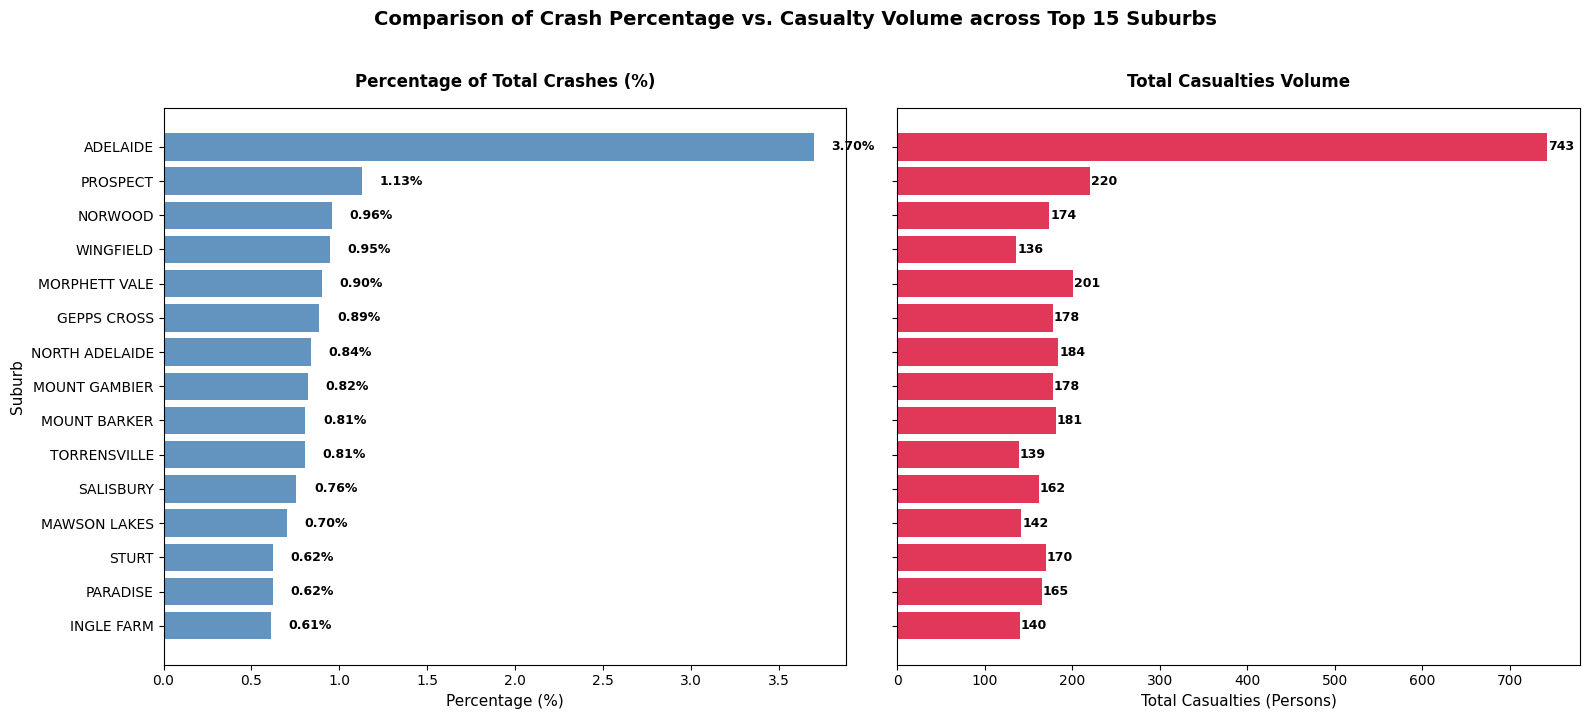

In [0]:
# Top 15 suburbs Group
top_15_suburbs = (crash_data['Suburb'].value_counts(normalize=True).head(15) * 100).sort_values(ascending=True)
top_15_names = top_15_suburbs.index
suburb_casualty_data = (
    crash_data[crash_data['Suburb'].isin(top_15_names)]
    .groupby('Suburb')
    .agg( Total_Crashes=('REPORT_ID', 'count'),Total_Casualties=('Total Cas', 'sum'),).loc[top_15_names])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

# Percent Total Crashes ---
bars1 = ax1.barh(
    top_15_suburbs.index, top_15_suburbs.values, color='steelblue', alpha=0.85)
ax1.set_title('Percentage of Total Crashes (%)', fontsize=12, fontweight='bold', pad=15)
ax1.set_xlabel('Percentage (%)', fontsize=11)
ax1.set_ylabel('Suburb', fontsize=11)
ax1.grid(False)  

for bar in bars1:
  width = bar.get_width()
  ax1.text(width + 0.1,
      bar.get_y() + bar.get_height() / 2,
      f'{width:.2f}%',
      va='center',
      ha='left',
      fontsize=9,
      fontweight='semibold',)
# Volume of Casualty
bars2 = ax2.barh(
    suburb_casualty_data.index,
    suburb_casualty_data['Total_Casualties'],
    color='crimson',
    alpha=0.85,)
ax2.set_title('Total Casualties Volume', fontsize=12, fontweight='bold', pad=15)
ax2.set_xlabel('Total Casualties (Persons)', fontsize=11)
ax2.grid(False)  

for bar in bars2:
  width = bar.get_width()
  ax2.text(
      width + 1,
      bar.get_y() + bar.get_height() / 2,
      f'{int(width)}',
      va='center',
      ha='left',
      fontsize=9,
      fontweight='semibold',)
#Title
plt.suptitle(
    'Comparison of Crash Percentage vs. Casualty Volume across Top 15 Suburbs',
    fontsize=14,
    fontweight='bold',
    y=1.02,)
plt.tight_layout()
plt.show()

#### 🔍 Key Takeaways from Top 15 Suburbs Comparison

- **Primary Hotspot:** **Adelaide** is the leading crash hotspot, accounting for **3.70%** of total crashes and generating **743 casualties**.
- **Secondary Peak:** **Prospect** ranks second in overall crash share (**1.13%**) and total casualties (**220 casualties**).
- **High Severity Outliers:** Suburbs like **Morphett Vale** (**201 casualties**)
---

### Speed Dynamics & Traffic Control Analysis

To evaluate how speed limits and traffic control infrastructure influence road safety, we analyze crash frequency and casualty counts across two dimensions:
- **Area Speed (`A. Crashes vs. Casualties by Area Speed`):** Explores the distribution and scale of crashes and casualties across specific posted speed zones (km/h).
- **Speed Groups & Control Signs (`B. Nested Comparison`):** Investigates the combined interaction between custom speed brackets and traffic control sign presence at incident locations.

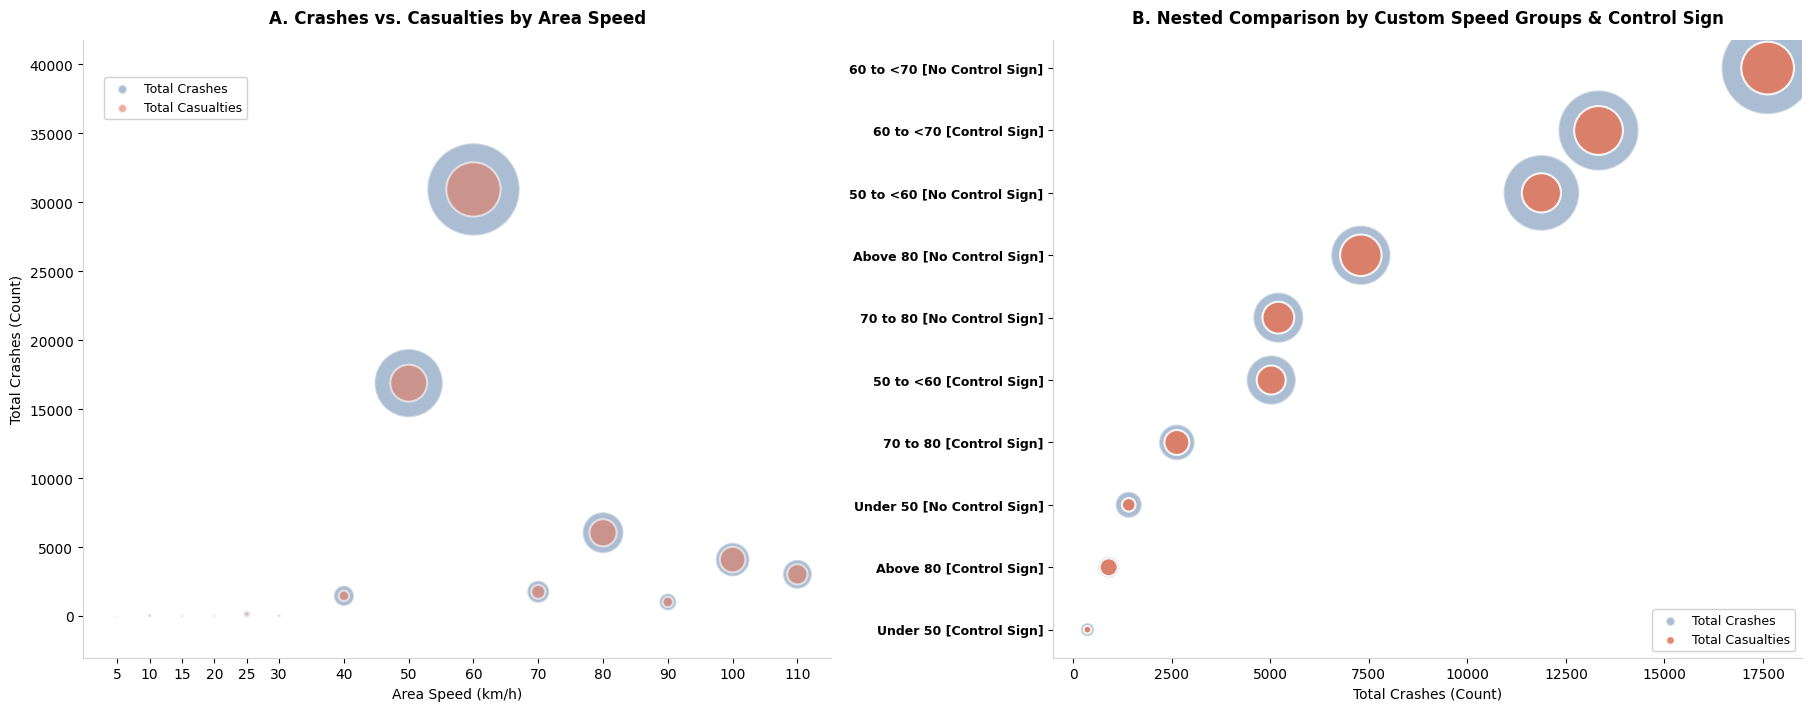

In [0]:
speed_analysis = (crash_data.groupby('Area Speed').agg(
        Total_Crashes=('REPORT_ID', 'count'),
        Total_Casualties=('Total Cas', 'sum'),).reset_index())
speed_analysis = speed_analysis[speed_analysis['Area Speed'] > 0]

df_grouped = (crash_data.groupby(['Speed_Group', 'Control Sign']).agg(
        Total_Crashes=('REPORT_ID', 'count'),
        Total_Casualties=('Total Cas', 'sum'),).reset_index())
df_grouped['Category'] = (df_grouped['Speed_Group'] + ' [' + df_grouped['Control Sign'] + ']')
df_grouped = df_grouped.sort_values(by='Total_Crashes', ascending=True)
#Plot setting
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 7), constrained_layout=True)
fig.patch.set_facecolor('white')
#Area Speed Plot
x1 = speed_analysis['Area Speed']
y1 = speed_analysis['Total_Crashes']
size_crashes_1 = speed_analysis['Total_Crashes'] / 7
size_casualties_1 = speed_analysis['Total_Casualties'] / 7
#Scatter Setting
ax1.scatter(
    x1,
    y1,
    s=size_crashes_1,
    color='#2b5c8f',
    alpha=0.4,
    edgecolors='white',
    linewidth=1.5,
    label='Total Crashes',)
ax1.scatter(
    x1,
    y1,
    s=size_casualties_1,
    color='#e07a5f',
    alpha=0.6,
    edgecolors='white',
    linewidth=1.5,
    label='Total Casualties',)
ax1.set_title('A. Crashes vs. Casualties by Area Speed', fontsize=12, fontweight='bold', pad=12)
ax1.set_xlabel('Area Speed (km/h)', fontsize=10)
ax1.set_ylabel('Total Crashes (Count)', fontsize=10)
ax1.set_xticks(sorted(x1.unique()))
ax1.set_ylim(-3000, max(y1) * 1.35)

ax1.grid(False)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_color('#D3D3D3')
ax1.spines['bottom'].set_color('#D3D3D3')

leg1 = ax1.legend(
    loc='upper left',
    bbox_to_anchor=(0.02, 0.95),
    framealpha=0.9,
    facecolor='white',
    edgecolor='#cccccc',
    fontsize=9,)
for handle in leg1.legend_handles:
  handle.set_sizes([40])


#Speed Group Plot
y_pos2 = np.arange(len(df_grouped))
size_crashes_2 = df_grouped['Total_Crashes'] / 4
size_casualties_2 = df_grouped['Total_Casualties'] / 4
#Scatter Setting
ax2.scatter(
    df_grouped['Total_Crashes'],
    y_pos2,
    s=size_crashes_2,
    color='#2b5c8f',
    alpha=0.4,
    edgecolors='white',
    linewidth=1.5,
    label='Total Crashes',)
ax2.scatter(
    df_grouped['Total_Crashes'],
    y_pos2,
    s=size_casualties_2,
    color='#e07a5f',
    alpha=0.9,
    edgecolors='white',
    linewidth=1.5,
    label='Total Casualties',)
ax2.set_yticks(y_pos2)
ax2.set_yticklabels(df_grouped['Category'], fontsize=9, fontweight='bold')
ax2.set_title('B. Nested Comparison by Custom Speed Groups & Control Sign',
    fontsize=12,
    fontweight='bold',
    pad=12,)
ax2.set_xlabel('Total Crashes (Count)', fontsize=10)
ax2.grid(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_color('#D3D3D3')
ax2.spines['bottom'].set_color('#D3D3D3')
leg2 = ax2.legend(
    loc='lower right',
    framealpha=0.9,
    facecolor='white',
    edgecolor='#cccccc',
    fontsize=9,)
for handle in leg2.legend_handles:
  handle.set_sizes([40])

plt.show()

#### 🔍 A. Crashes vs. Casualties by Area Speed
* **Concentration:** Incidents heavily concentrate in urban and suburban speed zones, peaking sharply at **60 km/h** (and secondary at **50 km/h**).
* **Volume:** Zones of **60 km/h** record the highest total crashes and casualties across the network.
---
#### 🔍 B. Nested Comparison by Speed Groups & Control Signs
* **High-Risk Categories:** Speed brackets between **60 to <70 km/h** and **50 to <60 km/h** under **[No Control Sign]** conditions account for the largest volume clusters.
* **Scale:** Uncontrolled mid-speed zones display the highest cumulative accident frequencies and severity footprints.
---

### Road Network Classification & Control Sign Regression

To examine how different road classifications and traffic management structures affect accident distribution, we analyze the data across two dimensions:
- **Road Group Breakdown (`A. Nested Comparison by Road Group`):** Compares total crash counts and casualties across distinct road network categories.
- **Bubble Regression Analysis (`B. Nested Bubble Regression Plot by Road Group & Control`):** Evaluates the correlation between crashes and casualties across combined road groups and control sign types, fitted with a linear regression trendline.

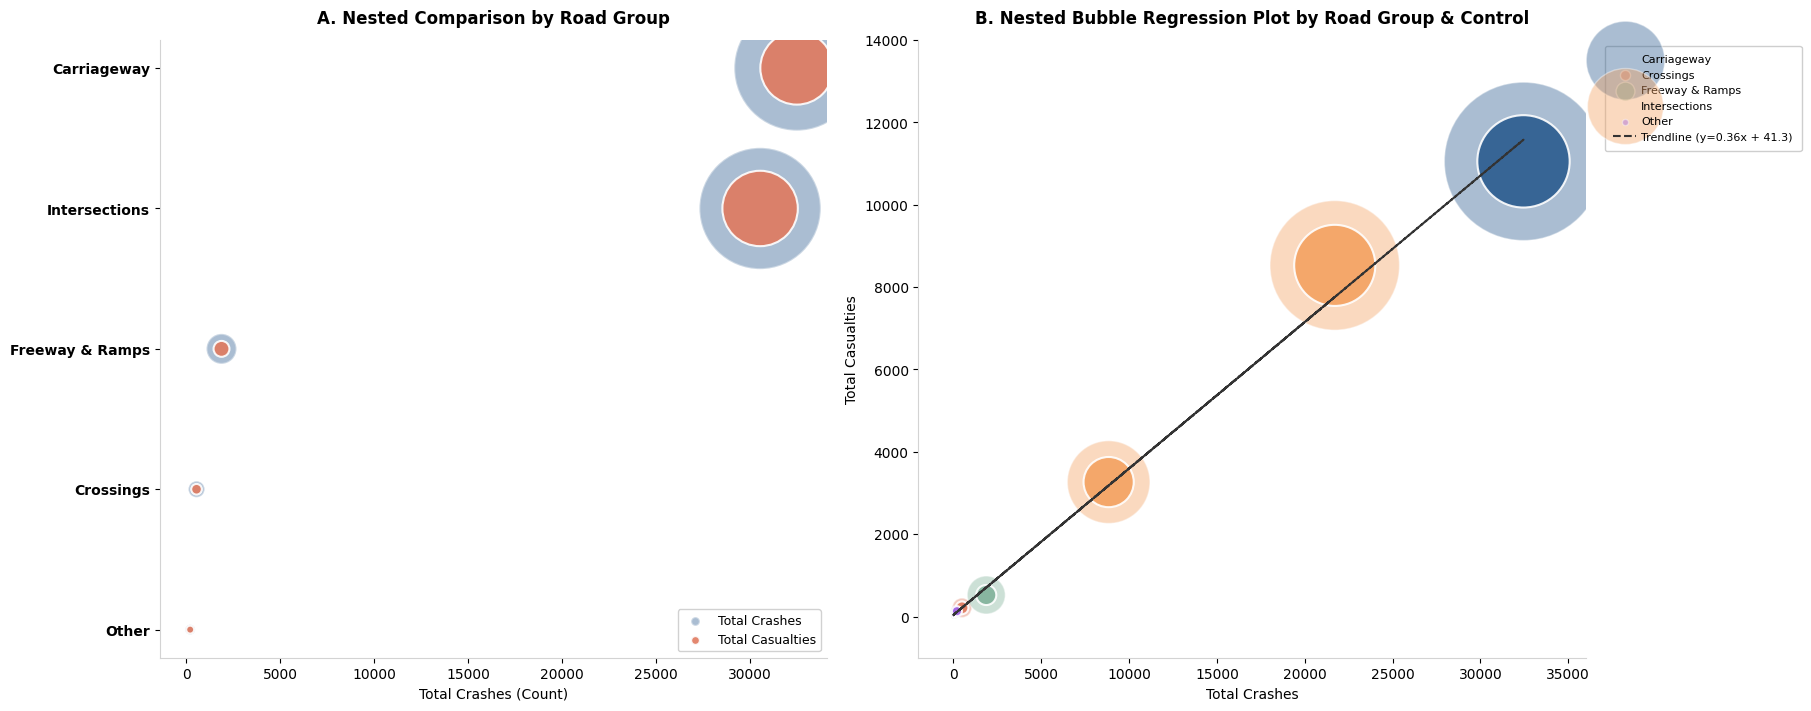

In [0]:
plt.style.use('default')
fig, (ax1, ax2) = plt.subplots(nrows=1, ncols=2, figsize=(18, 7), constrained_layout=True)
fig.patch.set_facecolor('white')
#Road Group Scatter
df_grouped_1 = (crash_data.groupby('Road Group').agg(
        Total_Crashes=('REPORT_ID', 'count'),
        Total_Casualties=('Total Cas', 'sum'),).reset_index())
df_grouped_1 = df_grouped_1.sort_values(by='Total_Crashes', ascending=True)
y_pos1 = np.arange(len(df_grouped_1))
size_crashes_1 = df_grouped_1['Total_Crashes'] / 4
size_casualties_1 = df_grouped_1['Total_Casualties'] / 4
ax1.scatter(
    df_grouped_1['Total_Crashes'],
    y_pos1,
    s=size_crashes_1,color='#2b5c8f',alpha=0.4, edgecolors='white',linewidth=1.5,label='Total Crashes',)
ax1.scatter(
    df_grouped_1['Total_Crashes'],
    y_pos1,
    s=size_casualties_1, color='#e07a5f',alpha=0.9,edgecolors='white', linewidth=1.5, label='Total Casualties',)
ax1.set_yticks(y_pos1)
ax1.set_yticklabels(
    df_grouped_1['Road Group'], fontsize=10, fontweight='bold')
ax1.set_xlabel('Total Crashes (Count)', fontsize=10)
ax1.set_title(
    'A. Nested Comparison by Road Group', fontsize=12, fontweight='bold', pad=12)
ax1.grid(False)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_color('#D3D3D3')
ax1.spines['bottom'].set_color('#D3D3D3')
leg1 = ax1.legend(
    loc='lower right',framealpha=0.9,facecolor='white',edgecolor='#cccccc',fontsize=9,)
for handle in leg1.legend_handles:
  handle.set_sizes([40])
#Road Group & Control Sign Bubble Regression 
df_grouped_2 = ( crash_data.groupby(['Road Group', 'Control Sign']).agg(
        Total_Crashes=('REPORT_ID', 'count'),
        Total_Casualties=('Total Cas', 'sum'),).reset_index())
x2 = df_grouped_2['Total_Crashes']
y2 = df_grouped_2['Total_Casualties']
groups = df_grouped_2['Road Group'].unique()
colors = ['#2b5c8f', '#e07a5f', '#81b29a', '#f4a261', '#9b5de5']
color_map = {grp: colors[i % len(colors)] for i, grp in enumerate(groups)}

# Vẽ vòng (Crashes)
for grp in groups:
  subset = df_grouped_2[df_grouped_2['Road Group'] == grp]
  ax2.scatter(
      subset['Total_Crashes'],
      subset['Total_Casualties'],
      s=subset['Total_Crashes'] / 2.5,
      color=color_map[grp],alpha=0.4,edgecolors='white',linewidth=1,label=grp,)
for grp in groups:
  subset = df_grouped_2[df_grouped_2['Road Group'] == grp]
  ax2.scatter(
      subset['Total_Crashes'],
      subset['Total_Casualties'],
      s=subset['Total_Casualties'] / 2.5,
      color=color_map[grp],alpha=0.9,edgecolors='white',linewidth=1.5,)

z = np.polyfit(x2, y2, 1)
p = np.poly1d(z)
ax2.plot(
    x2,
    p(x2),
    color='#333333',linestyle='--',linewidth=1.5,label=f'Trendline (y={z[0]:.2f}x + {z[1]:.1f})',)
ax2.set_xlim(-2000, 36000)
ax2.set_ylim(-1000, 14000)
ax2.set_title(
    'B. Nested Bubble Regression Plot by Road Group & Control',fontsize=12,fontweight='bold',pad=12,)
ax2.set_xlabel('Total Crashes', fontsize=10)
ax2.set_ylabel('Total Casualties', fontsize=10)
ax2.grid(False)
ax2.spines['top'].set_visible(False)
ax2.spines['right'].set_visible(False)
ax2.spines['left'].set_color('#D3D3D3')
ax2.spines['bottom'].set_color('#D3D3D3')
ax2.legend(
    bbox_to_anchor=(1.02, 1),loc='upper left',framealpha=0.95, facecolor='white',edgecolor='#cccccc', fontsize=8,markerscale=0.7,handletextpad=0.5, borderpad=0.8,)
plt.show()

#### 🔍 A. Road Group Comparison
* **High-Impact Zones:** **Carriageway** and **Intersections** record by far the highest volume of crashes (~30,000+ counts) and casualties.
* **Low-Volume Categories:** **Freeway & Ramps**, **Crossings**, and **Other** exhibit significantly lower incident frequencies (under 5,000 counts).

---

#### 🔍 B. Bubble Regression Analysis
* **Strong Linear Correlation:** The regression trendline ($y = 0.36x + 41.3$) demonstrates a highly consistent, proportional relationship between total crashes and total casualties across different road groups and control sign interactions.
* **Cluster Distribution:** Major infrastructure types (**Carriageway** and **Intersections**) cluster heavily at the upper-right high-volume end, whereas minor categories tightly cluster near the origin.
---

### 📌 Executive Summary

* **Scale & Temporal Trends:** Incident rates remained stable (2021–2025), peaking during rush hours (8:00 AM and 3:00–4:00 PM), weekdays, and mid-year months. 
* **Metropolitan areas** account for 79.9% of total crashes.
* **Hotspots & Infrastructure:** Adelaide and Prospect lead spatial hotspots. 
* **Carriageways and intersections** in **50–60 km/h zones** capture the highest absolute crash volumes.
* **Severity Drivers:** Unsealed roads, rainy weather, and substance impairment (DUI/Drugs) heavily amplify crash severity, with casualty ratios spiking from 90% up to 145% per incident
---

### Implications for Policy Makers

* **Targeted Infrastructure Upgrades:** Install traffic control signs, roundabouts, or signals in uncontrolled mid-speed urban zones (50–70 km/h).
* **Localized Enforcement:** Direct traffic policing and safety audits toward high-casualty hotspots
* **Strict Substance Deterrence:** Maintain aggressive roadside testing for DUI and drug involvement to curb extreme multi-casualty crashes
---

### Implications for Traffic Users
* **Peak-Hour Vigilance:** Exercise extra caution during morning and afternoon rush hours, particularly in dense urban corridors.
* **Adverse Condition Caution:** Reduce speed significantly when driving on unsealed roads or during wet weather.
* **Zero Impairment:** Strictly avoid driving under the influence of alcohol or drugs to eliminate catastrophic crash risks.